<a href="https://colab.research.google.com/github/Devansh070/BTP/blob/main/Draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Contact angle prediction from epsilon, time and trajectory-derived water flux features

In [1]:
import os
import re
import sys
import glob
import subprocess

try:
    import mdtraj
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "mdtraj"], check=True)
    import mdtraj

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False


def inputs_present():
    return len(glob.glob("*trajectory_alignment*.csv")) >= 1 and len(glob.glob("*.xtc")) >= 5


if IN_COLAB and not inputs_present():
    print("select the csv and all five xtc files")
    files.upload()

print("csv:", glob.glob("*.csv"))
print("xtc:", sorted(glob.glob("*.xtc")))

csv: ['contact_angle_trajectory_alignment.csv']
xtc: ['water_50ps_0.005.xtc', 'water_50ps_0.005_3layer.xtc', 'water_50ps_0.05.xtc', 'water_50ps_0.05_1layer.xtc', 'water_50ps_0.05_3layer.xtc', 'water_50ps_0.25.xtc', 'water_50ps_0.25_1layer.xtc', 'water_50ps_0.25_3layer.xtc', 'water_50ps_0.7.xtc', 'water_50ps_0.7_1layer.xtc', 'water_50ps_0.7_3layer.xtc', 'water_50ps_1.3.xtc', 'water_50ps_1.3_1layer.xtc', 'water_50ps_1.3_3layer.xtc']


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel, ConstantKernel
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from xgboost import XGBRegressor

try:
    import torch
    import torch.nn as nn
    HAS_TORCH = True
except ImportError:
    HAS_TORCH = False

warnings.filterwarnings("ignore")

SEED = 42
CSV_PATH = os.environ.get("CSV_PATH", (glob.glob("*trajectory_alignment*.csv") or ["contact_angle_trajectory_alignment.csv"])[0])
TRAJ_DIR = os.environ.get("TRAJ_DIR", os.path.dirname(os.path.abspath(CSV_PATH)))
TOPOLOGY_PATH = os.environ.get("TOPOLOGY_PATH", "")
OUT_DIR = os.environ.get("OUT_DIR", "outputs")
OXYGEN_STRIDE = 3
OXYGEN_OFFSET = 0
CV_RADIUS_NM = 2.0
CV_HEIGHT_NM = 1.0
TRAIN_TMAX_PS = 750
TRAJ_COLS = ["n_cv", "n_enter", "n_leave", "net_flux", "cum_enter", "cum_leave",
             "com_z", "height", "r_base", "rg", "cap_angle_est"]

os.makedirs(OUT_DIR, exist_ok=True)
np.random.seed(SEED)
if HAS_TORCH:
    torch.manual_seed(SEED)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("torch available:", HAS_TORCH)

torch available: True


## Load data and fill missing frames

In [3]:
raw = pd.read_csv(CSV_PATH).sort_values(["epsilon", "time_ps"]).reset_index(drop=True)


def fill_missing_frames(frame):
    parts = []
    for eps, g in frame.groupby("epsilon", sort=True):
        g = g.sort_values("time_ps").copy()
        g["source_time_ps"] = g["time_ps"]
        g["is_copied"] = False
        available = g[g["trajectory_frame_available"]]
        missing = ~g["trajectory_frame_available"]
        if missing.any() and len(available) > 0:
            last = available.iloc[-1]
            g.loc[missing, "contact_angle_deg"] = last["contact_angle_deg"]
            g.loc[missing, "source_time_ps"] = last["time_ps"]
            g.loc[missing, "is_copied"] = True
        parts.append(g)
    return pd.concat(parts, ignore_index=True)


df = fill_missing_frames(raw)
EPS_LIST = sorted(df["epsilon"].unique())
summary = df.groupby("epsilon").agg(
    total_frames=("time_ps", "size"),
    real_frames=("is_copied", lambda s: int((~s).sum())),
    copied_frames=("is_copied", "sum"),
)
display(summary)
display(df[df["epsilon"] == EPS_LIST[0]][["epsilon", "time_ps", "contact_angle_deg", "is_copied", "source_time_ps"]].head(6))

,total_frames,real_frames,copied_frames
epsilon,,,
0.005,20,2,18
0.050,20,20,0
0.250,20,20,0
0.700,20,20,0
1.300,20,20,0


,epsilon,time_ps,contact_angle_deg,is_copied,source_time_ps
0,0.005,50,134.185,False,50
1,0.005,100,137.644,False,100
2,0.005,150,137.644,True,100
3,0.005,200,137.644,True,100
4,0.005,250,137.644,True,100
5,0.005,300,137.644,True,100


## Trajectory features (water molecules entering or leaving the control volume)

In [4]:
def oxygen_indices(n_atoms):
    if TOPOLOGY_PATH and os.path.exists(TOPOLOGY_PATH):
        import mdtraj
        top = mdtraj.load(TOPOLOGY_PATH).topology
        idx = top.select("water and (name O or name OW)")
        if len(idx) > 0:
            return np.asarray(idx)
    return np.arange(OXYGEN_OFFSET, n_atoms, OXYGEN_STRIDE)


def load_oxygen_frames(path):
    from mdtraj.formats import XTCTrajectoryFile
    with XTCTrajectoryFile(path) as f:
        xyz, times, steps, box = f.read()
    ox = oxygen_indices(xyz.shape[1])
    return xyz[:, ox, :].astype(np.float64), np.asarray(times, dtype=float)


def pick_index(times, time_ps, frame_number):
    j = int(np.argmin(np.abs(times - time_ps)))
    if abs(times[j] - time_ps) <= 1e-3 * max(1.0, time_ps):
        return j
    k = int(frame_number)
    return min(k, len(times) - 1)


def find_traj_file(eps, listed_name):
    tag = format(float(eps), "g").replace(".", "_")
    pattern = re.compile(r"water_50ps_" + re.escape(tag) + r"(?:\s*\(\d+\))?\.xtc$")
    for name in sorted(os.listdir(TRAJ_DIR)):
        if pattern.search(name):
            return os.path.join(TRAJ_DIR, name)
    cand = os.path.join(TRAJ_DIR, listed_name)
    if os.path.exists(cand):
        return cand
    raise FileNotFoundError(f"no xtc file found for epsilon={eps} in {TRAJ_DIR}")


def traj_features_for_eps(eps, g):
    path = find_traj_file(eps, g["trajectory_file"].iloc[0])
    oxy, times = load_oxygen_frames(path)
    real = g[~g["is_copied"]].sort_values("time_ps")
    idxs = [pick_index(times, t, fn) for t, fn in zip(real["time_ps"], real["trajectory_frame_number"])]
    frames = [oxy[i] for i in idxs]
    z_surf = np.percentile(frames[0][:, 2], 1)
    center = frames[0][:, :2].mean(axis=0)
    rows = []
    prev = None
    cum_in = 0
    cum_out = 0
    for fr in frames:
        d = np.linalg.norm(fr[:, :2] - center, axis=1)
        inside = (d <= CV_RADIUS_NM) & (fr[:, 2] >= z_surf) & (fr[:, 2] <= z_surf + CV_HEIGHT_NM)
        if prev is None:
            n_in = 0
            n_out = 0
        else:
            n_in = int((inside & ~prev).sum())
            n_out = int((~inside & prev).sum())
        cum_in += n_in
        cum_out += n_out
        prev = inside
        z = fr[:, 2] - z_surf
        com = fr.mean(axis=0)
        xy = np.linalg.norm(fr[:, :2] - com[:2], axis=1)
        base = z <= 0.5
        r_base = np.percentile(xy[base], 95) if base.sum() >= 3 else np.percentile(xy, 95)
        height = np.percentile(z, 99)
        rg = np.sqrt(((fr - com) ** 2).sum(axis=1).mean())
        rows.append({
            "n_cv": int(inside.sum()), "n_enter": n_in, "n_leave": n_out, "net_flux": n_in - n_out,
            "cum_enter": cum_in, "cum_leave": cum_out, "com_z": z.mean(), "height": height,
            "r_base": r_base, "rg": rg,
            "cap_angle_est": 2.0 * np.degrees(np.arctan2(height, max(r_base, 1e-6))),
        })
    return pd.DataFrame(rows)


def attach_traj(frame):
    parts = []
    for eps, g in frame.groupby("epsilon", sort=True):
        g = g.sort_values("time_ps").reset_index(drop=True)
        tf = traj_features_for_eps(eps, g)
        for c in TRAJ_COLS:
            g[c] = np.nan
        real_mask = ~g["is_copied"].values
        g.loc[real_mask, TRAJ_COLS] = tf[TRAJ_COLS].values
        last = tf[TRAJ_COLS].iloc[-1]
        for c in TRAJ_COLS:
            g.loc[g["is_copied"], c] = last[c]
        parts.append(g)
    return pd.concat(parts, ignore_index=True)


try:
    df = attach_traj(df)
    USE_TRAJ = True
    df.to_csv(os.path.join(OUT_DIR, "trajectory_features.csv"), index=False)
    print("trajectory features extracted from xtc files")
except Exception as exc:
    USE_TRAJ = False
    print("trajectory features unavailable, using epsilon and time only:", repr(exc))

trajectory features unavailable, using epsilon and time only: FileNotFoundError('no xtc file found for epsilon=0.005 in /content')


## Feature engineering

In [5]:
df["log_eps"] = np.log10(df["epsilon"])
df["log_time"] = np.log10(df["time_ps"])
BASE_COLS = ["epsilon", "log_eps", "time_ps", "log_time"]
FEATURES = BASE_COLS + (TRAJ_COLS if USE_TRAJ else [])
PHYS_COLS = [FEATURES.index("log_eps"), FEATURES.index("time_ps")] + \
            [FEATURES.index(c) for c in TRAJ_COLS if c in FEATURES]
TARGET = "contact_angle_deg"
print(len(df), "rows |", len(FEATURES), "features:", FEATURES)

100 rows | 4 features: ['epsilon', 'log_eps', 'time_ps', 'log_time']


## Data overview

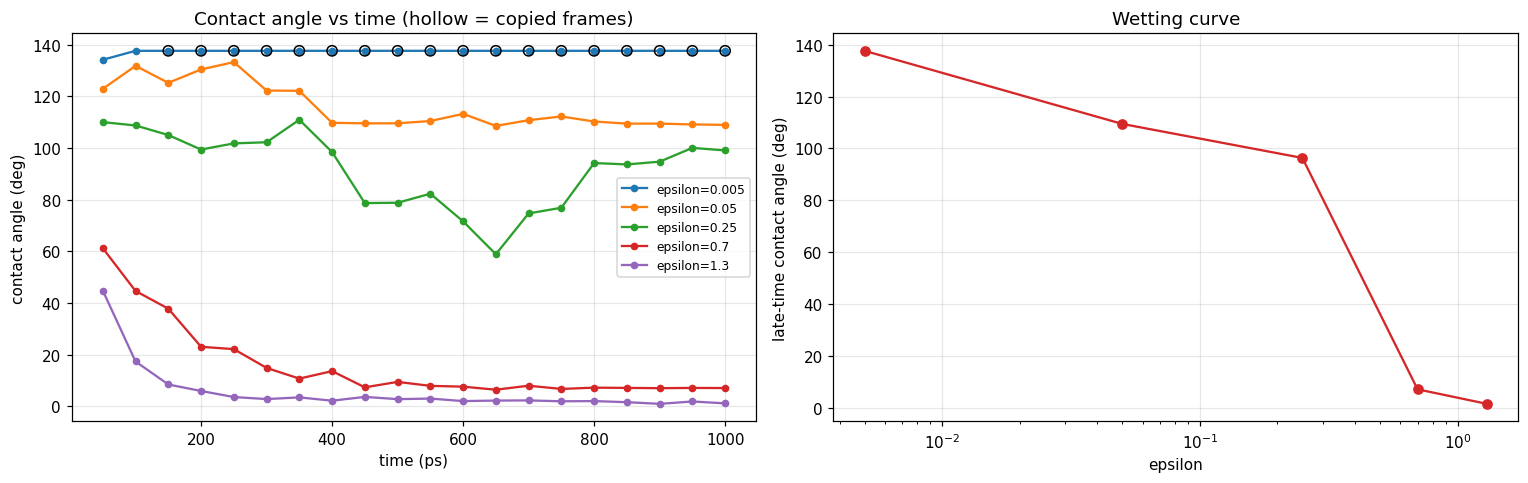

In [6]:
cmap = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, e in enumerate(EPS_LIST):
    g = df[df["epsilon"] == e]
    ax[0].plot(g["time_ps"], g[TARGET], "-o", color=cmap(i), ms=4, label=f"epsilon={e}")
    c = g[g["is_copied"]]
    ax[0].scatter(c["time_ps"], c[TARGET], facecolors="none", edgecolors="k", s=45, zorder=3)
ax[0].set_xlabel("time (ps)")
ax[0].set_ylabel("contact angle (deg)")
ax[0].set_title("Contact angle vs time (hollow = copied frames)")
ax[0].legend(fontsize=8)
eq = [df[df["epsilon"] == e].sort_values("time_ps").tail(5)[TARGET].mean() for e in EPS_LIST]
ax[1].semilogx(EPS_LIST, eq, "-o", color="tab:red")
ax[1].set_xlabel("epsilon")
ax[1].set_ylabel("late-time contact angle (deg)")
ax[1].set_title("Wetting curve")
plt.tight_layout()
plt.show()

if USE_TRAJ:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for i, e in enumerate(EPS_LIST):
        g = df[df["epsilon"] == e]
        ax[0].plot(g["time_ps"], g["n_cv"], "-o", ms=3, color=cmap(i), label=f"epsilon={e}")
        ax[1].plot(g["time_ps"], g["net_flux"], "-o", ms=3, color=cmap(i))
        ax[2].scatter(g["cap_angle_est"], g[TARGET], color=cmap(i), s=18)
    ax[0].set_title("Water molecules in control volume")
    ax[0].set_xlabel("time (ps)")
    ax[0].legend(fontsize=7)
    ax[1].set_title("Net flux (entering - leaving)")
    ax[1].set_xlabel("time (ps)")
    lim = [0, max(df["cap_angle_est"].max(), df[TARGET].max()) * 1.05]
    ax[2].plot(lim, lim, "k--", lw=1)
    ax[2].set_title("Geometric cap angle vs measured")
    ax[2].set_xlabel("cap_angle_est (deg)")
    ax[2].set_ylabel("contact angle (deg)")
    plt.tight_layout()
    plt.show()

## Models

In [7]:
def build_net(in_dim, hidden, depth):
    layers = []
    d = in_dim
    for _ in range(depth):
        layers += [nn.Linear(d, hidden), nn.SiLU()]
        d = hidden
    layers.append(nn.Linear(d, 1))
    return nn.Sequential(*layers)


if HAS_TORCH:
    class TorchMLP(BaseEstimator, RegressorMixin):
        def __init__(self, hidden=64, depth=3, epochs=2000, lr=3e-3, wd=1e-4, n_models=3, seed=SEED):
            self.hidden = hidden
            self.depth = depth
            self.epochs = epochs
            self.lr = lr
            self.wd = wd
            self.n_models = n_models
            self.seed = seed

        def fit(self, X, y):
            X = np.asarray(X, dtype=float)
            y = np.asarray(y, dtype=float)
            self.sx_ = StandardScaler().fit(X)
            Xs = torch.tensor(self.sx_.transform(X), dtype=torch.float32)
            yt = torch.tensor(y / 180.0, dtype=torch.float32).unsqueeze(1)
            self.nets_ = []
            for m in range(self.n_models):
                torch.manual_seed(self.seed + m)
                net = build_net(Xs.shape[1], self.hidden, self.depth)
                opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
                sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, self.epochs)
                for _ in range(self.epochs):
                    opt.zero_grad()
                    loss = ((net(Xs) - yt) ** 2).mean()
                    loss.backward()
                    opt.step()
                    sched.step()
                net.eval()
                self.nets_.append(net)
            return self

        def predict(self, X):
            Xs = torch.tensor(self.sx_.transform(np.asarray(X, dtype=float)), dtype=torch.float32)
            with torch.no_grad():
                out = np.mean([n(Xs).squeeze(1).numpy() for n in self.nets_], axis=0)
            return np.clip(out * 180.0, 0.0, 180.0)


    class PhysicsNN(BaseEstimator, RegressorMixin):
        def __init__(self, cols=None, hidden=64, depth=3, epochs=1500, lr=3e-3, wd=1e-4, n_models=3,
                     w_cos=0.5, w_mono=1.0, w_time=0.01, jitter=0.35, seed=SEED):
            self.cols = cols
            self.hidden = hidden
            self.depth = depth
            self.epochs = epochs
            self.lr = lr
            self.wd = wd
            self.n_models = n_models
            self.w_cos = w_cos
            self.w_mono = w_mono
            self.w_time = w_time
            self.jitter = jitter
            self.seed = seed

        def fit(self, X, y):
            X = np.asarray(X, dtype=float)[:, self.cols]
            y = np.asarray(y, dtype=float) / 180.0
            self.sx_ = StandardScaler().fit(X)
            Xs = torch.tensor(self.sx_.transform(X), dtype=torch.float32)
            yt = torch.tensor(y, dtype=torch.float32).unsqueeze(1)
            tmax = max(float(X[:, 1].max()), 1e-9)
            w = np.clip((X[:, 1] / tmax - 0.5) * 2.0, 0.0, 1.0)
            wt = torch.tensor(np.concatenate([w, w]), dtype=torch.float32)
            self.nets_ = []
            for m in range(self.n_models):
                torch.manual_seed(self.seed + m)
                net = build_net(Xs.shape[1], self.hidden, self.depth)
                opt = torch.optim.AdamW(net.parameters(), lr=self.lr, weight_decay=self.wd)
                sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, self.epochs)
                for _ in range(self.epochs):
                    opt.zero_grad()
                    p = torch.sigmoid(net(Xs))
                    data = ((p - yt) ** 2).mean() + self.w_cos * ((torch.cos(np.pi * p) - torch.cos(np.pi * yt)) ** 2).mean()
                    xj = Xs.clone()
                    xj[:, 0] = xj[:, 0] + self.jitter * torch.randn(xj.shape[0])
                    xa = torch.cat([Xs, xj], dim=0).requires_grad_(True)
                    pa = torch.sigmoid(net(xa))
                    g = torch.autograd.grad(pa.sum(), xa, create_graph=True)[0]
                    mono = (torch.relu(g[:, 0]) ** 2).mean()
                    late = (wt * g[:, 1] ** 2).mean()
                    loss = data + self.w_mono * mono + self.w_time * late
                    loss.backward()
                    opt.step()
                    sched.step()
                net.eval()
                self.nets_.append(net)
            return self

        def predict(self, X):
            X = np.asarray(X, dtype=float)[:, self.cols]
            Xs = torch.tensor(self.sx_.transform(X), dtype=torch.float32)
            with torch.no_grad():
                out = np.mean([torch.sigmoid(n(Xs)).squeeze(1).numpy() for n in self.nets_], axis=0)
            return out * 180.0


def scaled_target(reg):
    return TransformedTargetRegressor(regressor=reg, transformer=StandardScaler())


def poly_ridge(alpha, degree=3):
    nf = len(FEATURES)
    base_idx = list(range(len(BASE_COLS)))
    rest_idx = list(range(len(BASE_COLS), nf))
    parts = [("poly", make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False)), base_idx)]
    if rest_idx:
        parts.append(("rest", StandardScaler(), rest_idx))
    return make_pipeline(ColumnTransformer(parts), Ridge(alpha=alpha))


def make_models():
    models = {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Polynomial Ridge": poly_ridge(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=500, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                                                       subsample=0.9, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.9,
                                colsample_bytree=0.9, reg_lambda=1.0, random_state=SEED, n_jobs=-1),
        "SVR": scaled_target(make_pipeline(StandardScaler(), SVR(C=20.0, epsilon=0.02, gamma="scale"))),
        "Gaussian Process": scaled_target(make_pipeline(StandardScaler(), GaussianProcessRegressor(
            kernel=ConstantKernel(1.0) * RBF(length_scale=2.0) + WhiteKernel(1e-3),
            n_restarts_optimizer=3, random_state=SEED))),
        "MLP (sklearn)": scaled_target(make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 64), activation="tanh", solver="lbfgs", alpha=1e-3,
            max_iter=5000, random_state=SEED))),
    }
    if HAS_TORCH:
        models["Neural Network (PyTorch)"] = TorchMLP()
        models["Physics-Constrained NN"] = PhysicsNN(cols=PHYS_COLS)
    return models


MODELS = make_models()
ENSEMBLE_MEMBERS = [m for m in ["XGBoost", "Gaussian Process", "SVR", "Extra Trees",
                                "Neural Network (PyTorch)", "Physics-Constrained NN"] if m in MODELS]
print(list(MODELS))
print("ensemble members:", ENSEMBLE_MEMBERS)

['Linear Regression', 'Ridge', 'Polynomial Ridge', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost', 'SVR', 'Gaussian Process', 'MLP (sklearn)', 'Neural Network (PyTorch)', 'Physics-Constrained NN']
ensemble members: ['XGBoost', 'Gaussian Process', 'SVR', 'Extra Trees', 'Neural Network (PyTorch)', 'Physics-Constrained NN']


## Evaluation utilities

In [8]:
def metrics(y, p):
    p = np.clip(p, 0.0, 180.0)
    return {
        "MAE": mean_absolute_error(y, p),
        "RMSE": float(np.sqrt(mean_squared_error(y, p))),
        "R2": r2_score(y, p),
        "MaxAE": float(np.max(np.abs(y - p))),
    }


def run_protocol(frame, splits, models):
    out = []
    for sid, (tr, te) in enumerate(splits):
        Xtr = frame.loc[tr, FEATURES].values
        ytr = frame.loc[tr, TARGET].values
        Xte = frame.loc[te, FEATURES].values
        for name, mdl in models.items():
            est = clone(mdl).fit(Xtr, ytr)
            pred = np.clip(est.predict(Xte), 0.0, 180.0)
            out.append(pd.DataFrame({
                "model": name, "split": sid,
                "epsilon": frame.loc[te, "epsilon"].values,
                "time_ps": frame.loc[te, "time_ps"].values,
                "y": frame.loc[te, TARGET].values, "pred": pred,
            }))
        print(f"split {sid + 1}/{len(splits)} done")
    res = pd.concat(out, ignore_index=True)
    ens = (res[res["model"].isin(ENSEMBLE_MEMBERS)]
           .groupby(["split", "epsilon", "time_ps", "y"], as_index=False)["pred"].mean())
    ens["model"] = "Ensemble (avg)"
    return pd.concat([res, ens], ignore_index=True)


def score_table(res):
    rows = [{"model": name, **metrics(g["y"].values, g["pred"].values)} for name, g in res.groupby("model")]
    return pd.DataFrame(rows).sort_values("RMSE").reset_index(drop=True)

## Protocol A: temporal holdout (train t <= 750 ps, test t > 750 ps, real frames only)

In [9]:
real_mask = ~df["is_copied"].values
tr_idx = np.where(df["time_ps"].values <= TRAIN_TMAX_PS)[0]
te_idx = np.where((df["time_ps"].values > TRAIN_TMAX_PS) & real_mask)[0]
res_A = run_protocol(df, [(tr_idx, te_idx)], MODELS)
table_A = score_table(res_A)
print(f"train rows: {len(tr_idx)} | test rows: {len(te_idx)}")
display(table_A.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}", "MaxAE": "{:.3f}"}))
table_A.to_csv(os.path.join(OUT_DIR, "metrics_temporal_holdout.csv"), index=False)
res_A.to_csv(os.path.join(OUT_DIR, "predictions_temporal_holdout.csv"), index=False)

split 1/1 done
train rows: 75 | test rows: 20


,model,MAE,RMSE,R2,MaxAE
0,Ensemble (avg),8.476,9.870,0.9604,17.834
1,Extra Trees,5.764,9.923,0.9599,23.173
2,Gradient Boosting,5.872,10.312,0.9567,23.989
3,SVR,8.654,10.349,0.9564,21.396
4,XGBoost,5.963,10.440,0.9557,24.241
5,Random Forest,6.084,10.950,0.9512,25.340
6,Polynomial Ridge,9.398,11.974,0.9417,29.026
7,Physics-Constrained NN,8.367,12.181,0.9396,36.835
8,Neural Network (PyTorch),11.597,13.128,0.9299,21.741
9,Gaussian Process,11.981,13.449,0.9264,27.683


## Protocol B: leave-one-epsilon-out (train on the other epsilons, test on the held-out epsilon)

In [10]:
splits_B = [(np.where(df["epsilon"].values != e)[0],
             np.where((df["epsilon"].values == e) & real_mask)[0]) for e in EPS_LIST]
res_B = run_protocol(df, splits_B, MODELS)
interior = EPS_LIST[1:-1]
table_B_all = score_table(res_B)
table_B_int = score_table(res_B[res_B["epsilon"].isin(interior)])
print("pooled over all held-out epsilons (includes the two extrapolation ends)")
display(table_B_all.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}", "MaxAE": "{:.3f}"}))
print(f"interior epsilons only {interior}")
display(table_B_int.style.format({"MAE": "{:.3f}", "RMSE": "{:.3f}", "R2": "{:.4f}", "MaxAE": "{:.3f}"}))
per_eps = (res_B.assign(abs_err=(res_B["y"] - res_B["pred"]).abs())
           .pivot_table(index="model", columns="epsilon", values="abs_err", aggfunc="mean")
           .round(2))
print("MAE per held-out epsilon")
display(per_eps)
table_B_all.to_csv(os.path.join(OUT_DIR, "metrics_leave_one_epsilon_out_all.csv"), index=False)
table_B_int.to_csv(os.path.join(OUT_DIR, "metrics_leave_one_epsilon_out_interior.csv"), index=False)
res_B.to_csv(os.path.join(OUT_DIR, "predictions_leave_one_epsilon_out.csv"), index=False)

split 1/5 done
split 2/5 done
split 3/5 done
split 4/5 done
split 5/5 done
pooled over all held-out epsilons (includes the two extrapolation ends)


,model,MAE,RMSE,R2,MaxAE
0,Gradient Boosting,18.068,23.224,0.7836,52.894
1,Random Forest,18.526,23.228,0.7835,46.009
2,Extra Trees,19.133,24.022,0.7685,49.708
3,Ridge,19.785,25.230,0.7446,45.815
4,Linear Regression,19.948,25.421,0.7407,45.815
5,Physics-Constrained NN,18.857,25.861,0.7316,64.752
6,Ensemble (avg),23.766,26.143,0.7257,53.895
7,Neural Network (PyTorch),22.160,26.787,0.7121,54.117
8,MLP (sklearn),21.818,28.925,0.6643,70.440
9,Polynomial Ridge,24.708,33.157,0.5589,71.262


interior epsilons only [np.float64(0.05), np.float64(0.25), np.float64(0.7)]


,model,MAE,RMSE,R2,MaxAE
0,Gradient Boosting,21.021,26.101,0.6571,52.894
1,Random Forest,21.783,26.209,0.6542,46.009
2,Extra Trees,22.479,27.071,0.6311,49.708
3,Ensemble (avg),24.399,27.357,0.6233,53.895
4,SVR,24.745,27.443,0.6209,55.613
5,Ridge,23.676,27.627,0.6158,44.119
6,Gaussian Process,25.129,27.837,0.6099,54.253
7,Linear Regression,23.898,27.865,0.6092,45.427
8,Physics-Constrained NN,24.130,29.796,0.5531,64.752
9,Neural Network (PyTorch),27.582,30.318,0.5373,54.117


MAE per held-out epsilon


epsilon,0.005,0.050,0.250,0.700,1.300
model,,,,,
Ensemble (avg),24.78,16.96,19.70,36.54,21.76
Extra Trees,8.55,5.74,26.10,35.60,10.15
Gaussian Process,62.46,19.22,24.05,32.12,69.17
Gradient Boosting,8.76,6.74,17.22,39.10,10.14
Linear Regression,44.09,8.99,26.30,36.40,5.68
MLP (sklearn),44.24,31.22,21.84,27.95,4.01
Neural Network (PyTorch),24.24,20.75,25.40,36.60,5.68
Physics-Constrained NN,5.78,19.14,41.43,11.82,4.34
Polynomial Ridge,51.99,9.11,25.51,55.80,5.68


## Plots

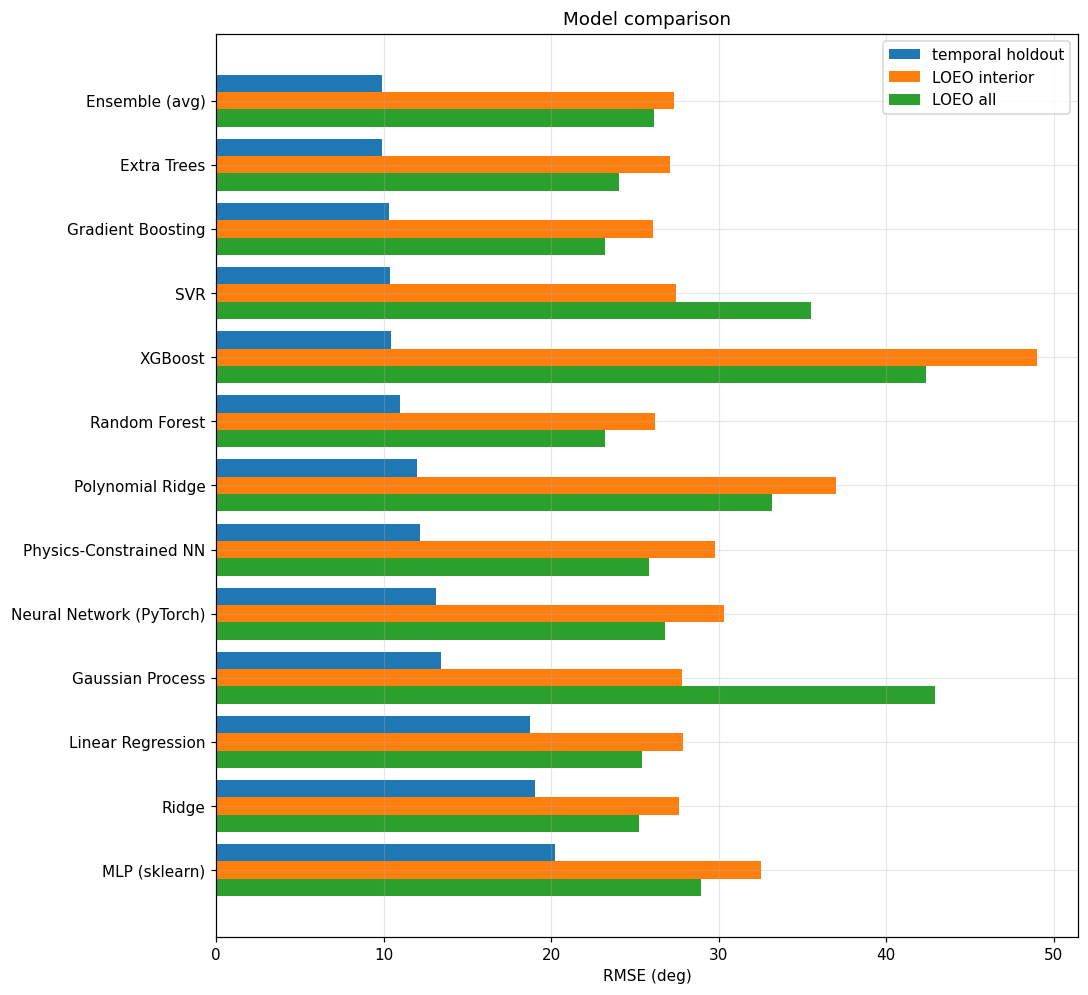

In [11]:
cmp = table_A[["model", "RMSE"]].merge(table_B_int[["model", "RMSE"]], on="model", suffixes=("_temporal", "_LOEO_interior"))
cmp = cmp.merge(table_B_all[["model", "RMSE"]].rename(columns={"RMSE": "RMSE_LOEO_all"}), on="model")
cmp = cmp.sort_values("RMSE_temporal")
y = np.arange(len(cmp))
fig, ax = plt.subplots(figsize=(10, 0.55 * len(cmp) + 2))
ax.barh(y - 0.27, cmp["RMSE_temporal"], 0.27, label="temporal holdout")
ax.barh(y, cmp["RMSE_LOEO_interior"], 0.27, label="LOEO interior")
ax.barh(y + 0.27, cmp["RMSE_LOEO_all"], 0.27, label="LOEO all")
ax.set_yticks(y)
ax.set_yticklabels(cmp["model"])
ax.invert_yaxis()
ax.set_xlabel("RMSE (deg)")
ax.set_title("Model comparison")
ax.legend()
plt.tight_layout()
plt.show()

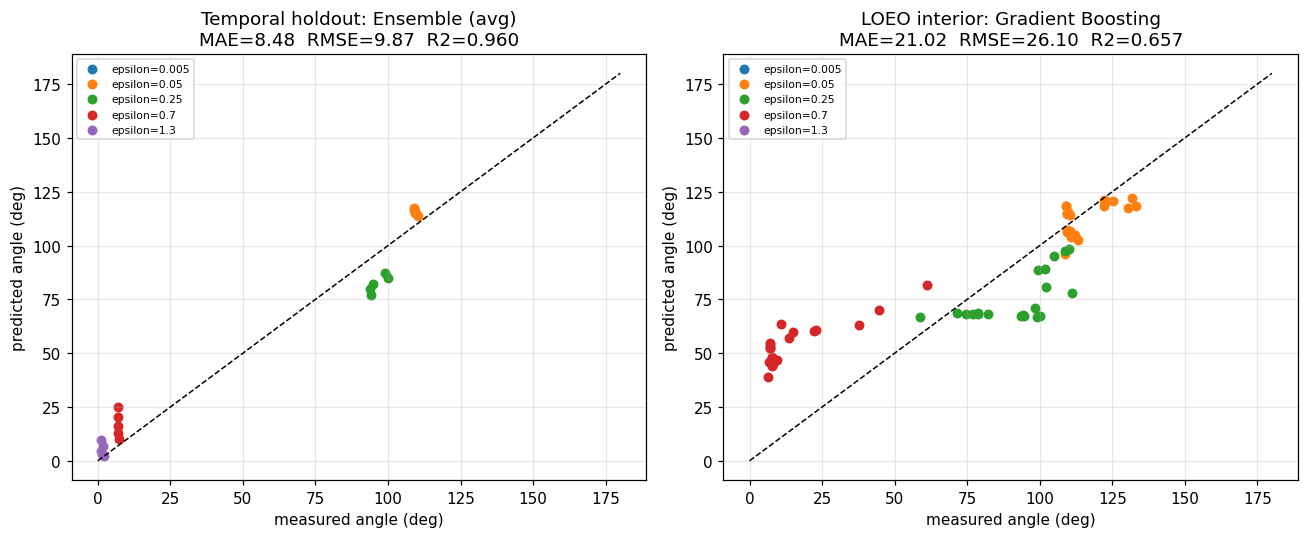

In [12]:
best_A = table_A.iloc[0]["model"]
best_B = table_B_int.iloc[0]["model"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, res, name, title in [(ax[0], res_A, best_A, "Temporal holdout"),
                            (ax[1], res_B[res_B["epsilon"].isin(interior)], best_B, "LOEO interior")]:
    g = res[res["model"] == name]
    for i, e in enumerate(EPS_LIST):
        s = g[g["epsilon"] == e]
        a.scatter(s["y"], s["pred"], color=cmap(i), s=30, label=f"epsilon={e}")
    lim = [0, 180]
    a.plot(lim, lim, "k--", lw=1)
    m = metrics(g["y"].values, g["pred"].values)
    a.set_title(f"{title}: {name}\nMAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}  R2={m['R2']:.3f}")
    a.set_xlabel("measured angle (deg)")
    a.set_ylabel("predicted angle (deg)")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

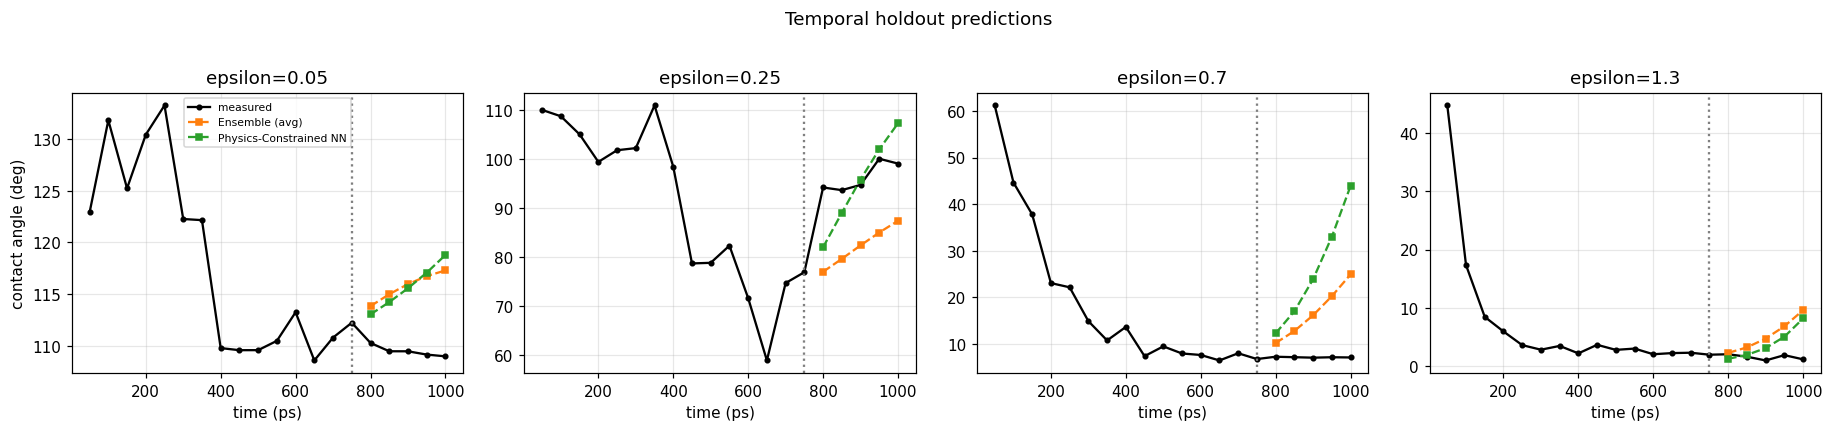

In [13]:
show = [best_A]
for extra in ["Physics-Constrained NN", "Ensemble (avg)"]:
    if extra in set(res_A["model"]) and extra not in show:
        show.append(extra)
eps_A = sorted(res_A["epsilon"].unique())
fig, axes = plt.subplots(1, len(eps_A), figsize=(4.2 * len(eps_A), 3.8), sharey=False)
axes = np.atleast_1d(axes)
for a, e in zip(axes, eps_A):
    g = df[(df["epsilon"] == e) & (~df["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    a.axvline(TRAIN_TMAX_PS, color="gray", ls=":")
    for k, name in enumerate(show):
        s = res_A[(res_A["model"] == name) & (res_A["epsilon"] == e)].sort_values("time_ps")
        a.plot(s["time_ps"], s["pred"], "--s", ms=4, color=cmap(k + 1), label=name)
    a.set_title(f"epsilon={e}")
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=7)
plt.suptitle("Temporal holdout predictions", y=1.02)
plt.tight_layout()
plt.show()

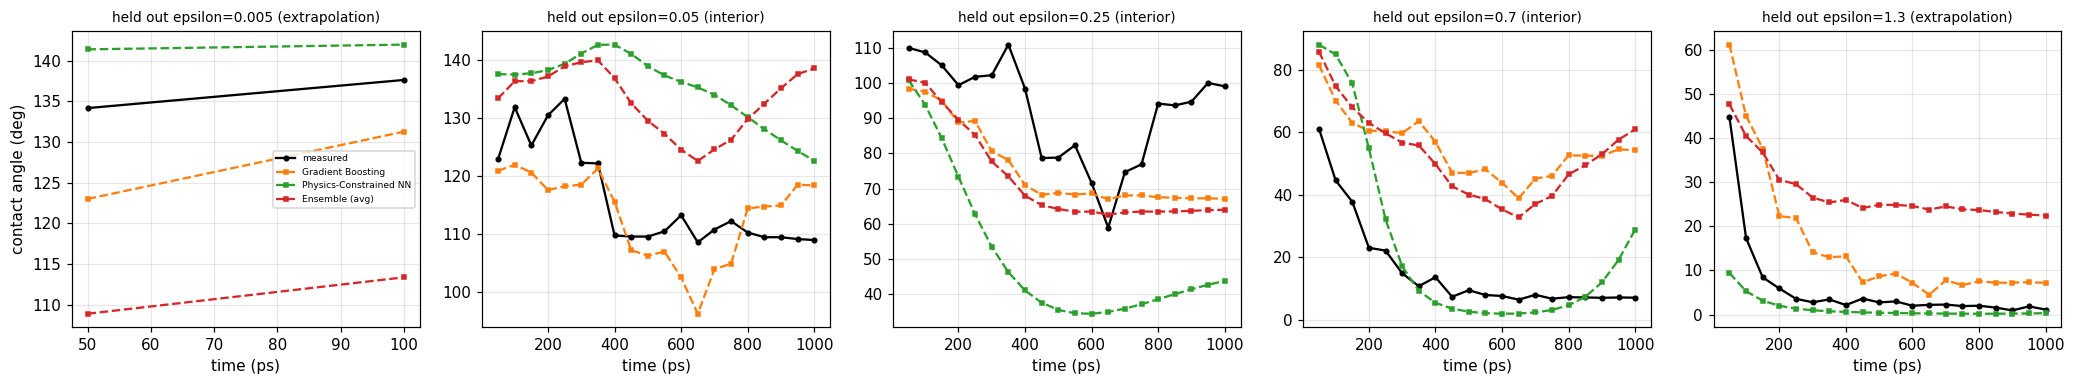

In [14]:
fig, axes = plt.subplots(1, len(EPS_LIST), figsize=(3.8 * len(EPS_LIST), 3.6))
for a, e in zip(axes, EPS_LIST):
    g = df[(df["epsilon"] == e) & (~df["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    for k, name in enumerate(dict.fromkeys([best_B, "Physics-Constrained NN", "Ensemble (avg)"])):
        s = res_B[(res_B["model"] == name) & (res_B["epsilon"] == e)].sort_values("time_ps")
        if len(s):
            a.plot(s["time_ps"], s["pred"], "--s", ms=3, color=cmap(k + 1), label=name)
    tag = "interior" if e in interior else "extrapolation"
    a.set_title(f"held out epsilon={e} ({tag})", fontsize=9)
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=6)
plt.tight_layout()
plt.show()

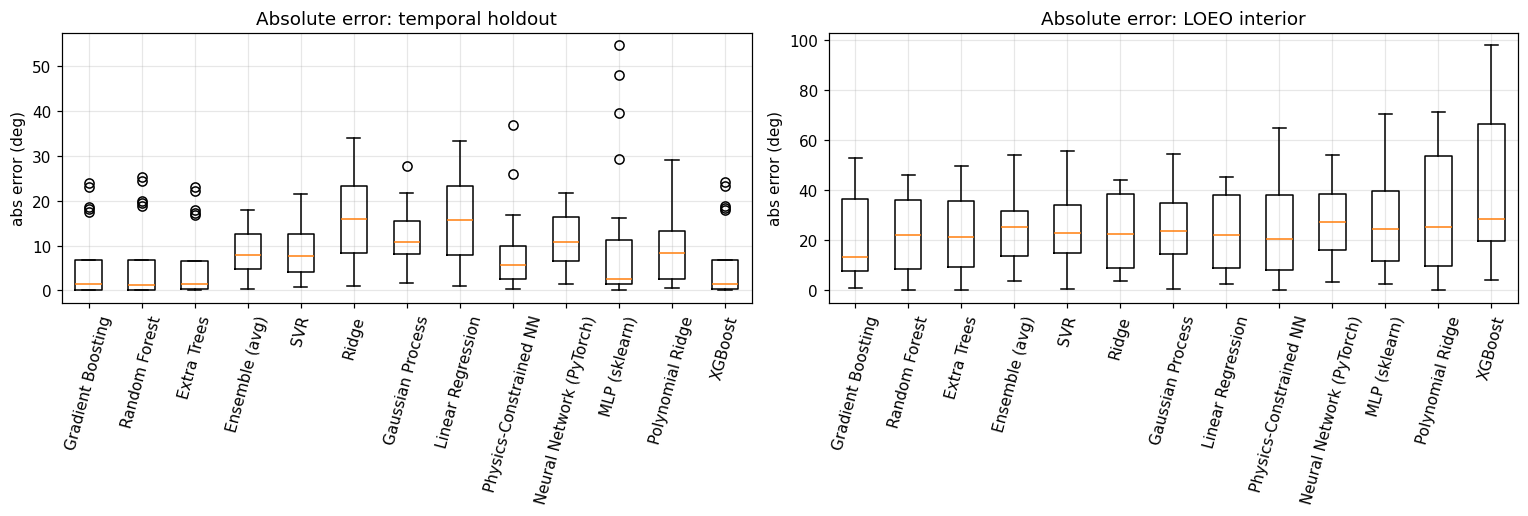

In [15]:
order = table_B_int["model"].tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ea = res_A.assign(err=(res_A["y"] - res_A["pred"]).abs())
eb = res_B[res_B["epsilon"].isin(interior)]
eb = eb.assign(err=(eb["y"] - eb["pred"]).abs())
for a, e_df, title in [(ax[0], ea, "Absolute error: temporal holdout"), (ax[1], eb, "Absolute error: LOEO interior")]:
    names = [m for m in order if m in set(e_df["model"])]
    a.boxplot([e_df[e_df["model"] == m]["err"].values for m in names], showfliers=True)
    a.set_xticklabels(names)
    a.set_title(title)
    a.set_ylabel("abs error (deg)")
    a.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

In [16]:
if USE_TRAJ and "XGBoost" in MODELS:
    xgb = clone(MODELS["XGBoost"]).fit(df[FEATURES].values, df[TARGET].values)
    imp = pd.Series(xgb.feature_importances_, index=FEATURES).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp) + 1.5))
    ax.barh(imp.index, imp.values, color="tab:blue")
    ax.set_title("XGBoost feature importance (trained on all rows)")
    plt.tight_layout()
    plt.show()

## Final summary

In [17]:
final = pd.DataFrame({
    "temporal_RMSE": table_A.set_index("model")["RMSE"],
    "temporal_R2": table_A.set_index("model")["R2"],
    "LOEO_interior_RMSE": table_B_int.set_index("model")["RMSE"],
    "LOEO_interior_R2": table_B_int.set_index("model")["R2"],
    "LOEO_all_RMSE": table_B_all.set_index("model")["RMSE"],
}).sort_values("temporal_RMSE")
display(final.round(3))
final.to_csv(os.path.join(OUT_DIR, "final_summary.csv"))
print("features used:", FEATURES)
print("trajectory features used:", USE_TRAJ)
print("outputs saved to:", os.path.abspath(OUT_DIR))

,temporal_RMSE,temporal_R2,LOEO_interior_RMSE,LOEO_interior_R2,LOEO_all_RMSE
model,,,,,
Ensemble (avg),9.870,0.960,27.357,0.623,26.143
Extra Trees,9.923,0.960,27.071,0.631,24.022
Gradient Boosting,10.312,0.957,26.101,0.657,23.224
SVR,10.349,0.956,27.443,0.621,35.504
XGBoost,10.440,0.956,49.001,-0.209,42.401
Random Forest,10.950,0.951,26.209,0.654,23.228
Polynomial Ridge,11.974,0.942,37.020,0.310,33.157
Physics-Constrained NN,12.181,0.940,29.796,0.553,25.861
Neural Network (PyTorch),13.128,0.930,30.318,0.537,26.787


features used: ['epsilon', 'log_eps', 'time_ps', 'log_time']
trajectory features used: False
outputs saved to: /content/outputs


# Dataset g1: single carbon plane (from the .gro files), epsilon 0.05, 0.25, 0.7, 1.3

This section is independent of the dataset above: its own data, features, models and results, all with the suffix _g1. It reuses only generic helpers defined earlier (imports, constants, PyTorch classes, metrics, pick_index).

In [18]:
DATA_DIR_g1 = os.environ.get("DATA_DIR_g1", os.getcwd())


def count_xtc_g1():
    return len(glob.glob(os.path.join(DATA_DIR_g1, "*_1layer*.xtc")))


if IN_COLAB and count_xtc_g1() < 4:
    print("select the 4 xtc files (for example water_50ps_0.05_1layer.xtc) and the 4 frame0 gro files of this dataset")
    files.upload()

print("1layer xtc:", sorted(glob.glob(os.path.join(DATA_DIR_g1, "*_1layer*.xtc"))))
print("gro:", sorted(glob.glob(os.path.join(DATA_DIR_g1, "frame0_*.gro"))))

1layer xtc: ['/content/water_50ps_0.05_1layer.xtc', '/content/water_50ps_0.25_1layer.xtc', '/content/water_50ps_0.7_1layer.xtc', '/content/water_50ps_1.3_1layer.xtc']
gro: ['/content/frame0_0.005_3layer.gro', '/content/frame0_0.05.gro', '/content/frame0_0.05_3layer.gro', '/content/frame0_0.25.gro', '/content/frame0_0.25_3layer.gro', '/content/frame0_0.7.gro', '/content/frame0_0.7_3layer.gro', '/content/frame0_1.3.gro', '/content/frame0_1.3_3layer.gro']


## Load data

In [19]:
TIMES_g1 = np.arange(50, 1001, 50)
ANGLES_g1 = {
    0.05: [134.031, 135.222, 123.205, 112.725, 129.879, 125.348, 125.720, 118.415, 114.649, 111.361,
           107.514, 122.163, 120.876, 118.478, 119.384, 114.592, 113.279, 112.127, 110.389, 108.061],
    0.25: [111.210, 118.260, 111.643, 113.493, 92.790, 96.488, 108.882, 107.335, 94.604, 99.024,
           101.252, 108.845, 111.930, 108.109, 113.985, 116.411, 94.159, 94.764, 105.213, 108.291],
    0.7: [72.369, 48.407, 39.336, 33.883, 27.312, 21.599, 26.100, 25.645, 20.937, 18.944,
          18.554, 24.321, 14.890, 16.395, 15.946, 13.418, 13.760, 13.752, 15.882, 13.782],
    1.3: [49.802, 23.216, 10.976, 3.249, 3.460, 2.587, 2.182, 1.868, 2.018, 1.654,
          1.650, 2.253, 1.879, 1.581, 1.647, 1.578, 1.538, 1.647, 1.582, 1.384],
}
assert all(len(v) == len(TIMES_g1) for v in ANGLES_g1.values())

rows_g1 = []
for e, vals in ANGLES_g1.items():
    tag = format(e, "g")
    for k, (t, a) in enumerate(zip(TIMES_g1, vals), start=1):
        rows_g1.append({
            "epsilon": e, "time_ps": float(t), "contact_angle_deg": a,
            "trajectory_file": f"water_50ps_{tag}_1layer.xtc", "trajectory_frame_number": float(k),
            "trajectory_frame_available": True,
        })
raw_g1 = pd.DataFrame(rows_g1).sort_values(["epsilon", "time_ps"]).reset_index(drop=True)
df_g1 = fill_missing_frames(raw_g1)
EPS_LIST_g1 = sorted(df_g1["epsilon"].unique())
summary_g1 = df_g1.groupby("epsilon").agg(
    total_frames=("time_ps", "size"),
    real_frames=("is_copied", lambda s: int((~s).sum())),
    copied_frames=("is_copied", "sum"),
)
display(summary_g1)


def read_gro_g1(path):
    with open(path) as f:
        lines = f.read().split("\n")
    n = int(lines[1])
    resn = []
    names = []
    xyz = []
    for ln in lines[2:2 + n]:
        resn.append(ln[5:10].strip())
        names.append(ln[10:15].strip())
        xyz.append([float(ln[20:28]), float(ln[28:36]), float(ln[36:44])])
    return np.array(resn), np.array(names), np.array(xyz)


def find_data_file_g1(eps, prefix, suffix, ext):
    tag = re.escape(format(float(eps), "g")).replace(r"\.", "[._]")
    pattern = re.compile(prefix + tag + suffix + r"(?: \(\d+\))?\." + ext + "$")
    for name in sorted(os.listdir(DATA_DIR_g1)):
        if pattern.search(name):
            return os.path.join(DATA_DIR_g1, name)
    raise FileNotFoundError(f"no {ext} file for epsilon={eps} in {DATA_DIR_g1}")


substrate_rows_g1 = []
for e in EPS_LIST_g1:
    try:
        resn, names, xyz0 = read_gro_g1(find_data_file_g1(e, "frame0_", "(?:_1layer)?", "gro"))
    except FileNotFoundError:
        continue
    sub = resn != "SOL"
    z = xyz0[sub, 2]
    substrate_rows_g1.append({
        "epsilon": e, "substrate_atoms": int(sub.sum()), "water_atoms": int((~sub).sum()),
        "substrate_planes": int(np.unique(np.round(z, 2)).size), "plane_z_nm": float(z.mean()),
    })
if substrate_rows_g1:
    display(pd.DataFrame(substrate_rows_g1))

,total_frames,real_frames,copied_frames
epsilon,,,
0.05,20,20,0
0.25,20,20,0
0.70,20,20,0
1.30,20,20,0


,epsilon,substrate_atoms,water_atoms,substrate_planes,plane_z_nm
0,0.05,9880,12465,1,18.409
1,0.25,9880,12465,1,18.409
2,0.70,9880,12465,1,18.409
3,1.30,9880,12465,1,18.409


## Trajectory features

In [20]:
def oxygen_index_g1(eps, n_atoms):
    try:
        resn, names, xyz0 = read_gro_g1(find_data_file_g1(eps, "frame0_", "(?:_1layer)?", "gro"))
    except FileNotFoundError:
        return np.arange(OXYGEN_OFFSET, n_atoms, OXYGEN_STRIDE)
    water = np.where(resn == "SOL")[0]
    if n_atoms == len(water):
        return np.where(names[water] == "OW")[0]
    if n_atoms == len(names):
        return np.where((resn == "SOL") & (names == "OW"))[0]
    return np.arange(OXYGEN_OFFSET, n_atoms, OXYGEN_STRIDE)


def load_oxygen_frames_g1(path, eps):
    from mdtraj.formats import XTCTrajectoryFile
    with XTCTrajectoryFile(path) as f:
        xyz, times, steps, box = f.read()
    ox = oxygen_index_g1(eps, xyz.shape[1])
    return xyz[:, ox, :].astype(np.float64), np.asarray(times, dtype=float)


def traj_features_for_eps_g1(eps, g):
    path = find_data_file_g1(eps, "water_50ps_", "_1layer", "xtc")
    oxy, times = load_oxygen_frames_g1(path, eps)
    real = g[~g["is_copied"]].sort_values("time_ps")
    idxs = [pick_index(times, t, fn) for t, fn in zip(real["time_ps"], real["trajectory_frame_number"])]
    frames = [oxy[i] for i in idxs]
    z_surf = np.percentile(frames[0][:, 2], 1)
    center = frames[0][:, :2].mean(axis=0)
    rows = []
    prev = None
    cum_in = 0
    cum_out = 0
    for fr in frames:
        d = np.linalg.norm(fr[:, :2] - center, axis=1)
        inside = (d <= CV_RADIUS_NM) & (fr[:, 2] >= z_surf) & (fr[:, 2] <= z_surf + CV_HEIGHT_NM)
        if prev is None:
            n_in = 0
            n_out = 0
        else:
            n_in = int((inside & ~prev).sum())
            n_out = int((~inside & prev).sum())
        cum_in += n_in
        cum_out += n_out
        prev = inside
        z = fr[:, 2] - z_surf
        com = fr.mean(axis=0)
        xy = np.linalg.norm(fr[:, :2] - com[:2], axis=1)
        base = z <= 0.5
        r_base = np.percentile(xy[base], 95) if base.sum() >= 3 else np.percentile(xy, 95)
        height = np.percentile(z, 99)
        rg = np.sqrt(((fr - com) ** 2).sum(axis=1).mean())
        rows.append({
            "n_cv": int(inside.sum()), "n_enter": n_in, "n_leave": n_out, "net_flux": n_in - n_out,
            "cum_enter": cum_in, "cum_leave": cum_out, "com_z": z.mean(), "height": height,
            "r_base": r_base, "rg": rg,
            "cap_angle_est": 2.0 * np.degrees(np.arctan2(height, max(r_base, 1e-6))),
        })
    return pd.DataFrame(rows)


def attach_traj_g1(frame):
    parts = []
    for eps, g in frame.groupby("epsilon", sort=True):
        g = g.sort_values("time_ps").reset_index(drop=True)
        tf = traj_features_for_eps_g1(eps, g)
        for c in TRAJ_COLS:
            g[c] = np.nan
        real_mask = ~g["is_copied"].values
        g.loc[real_mask, TRAJ_COLS] = tf[TRAJ_COLS].values
        last = tf[TRAJ_COLS].iloc[-1]
        for c in TRAJ_COLS:
            g.loc[g["is_copied"], c] = last[c]
        parts.append(g)
    return pd.concat(parts, ignore_index=True)


try:
    df_g1 = attach_traj_g1(df_g1)
    USE_TRAJ_g1 = True
    df_g1.to_csv(os.path.join(OUT_DIR, "g1_trajectory_features.csv"), index=False)
    print("trajectory features extracted from xtc files")
except Exception as exc:
    USE_TRAJ_g1 = False
    print("trajectory features unavailable, using epsilon and time only:", repr(exc))

trajectory features extracted from xtc files


## Feature engineering

In [21]:
df_g1["log_eps"] = np.log10(df_g1["epsilon"])
df_g1["log_time"] = np.log10(df_g1["time_ps"])
FEATURES_g1 = BASE_COLS + (TRAJ_COLS if USE_TRAJ_g1 else [])
PHYS_COLS_g1 = [FEATURES_g1.index("log_eps"), FEATURES_g1.index("time_ps")] + \
               [FEATURES_g1.index(c) for c in TRAJ_COLS if c in FEATURES_g1]
print(len(df_g1), "rows |", len(FEATURES_g1), "features:", FEATURES_g1)

80 rows | 15 features: ['epsilon', 'log_eps', 'time_ps', 'log_time', 'n_cv', 'n_enter', 'n_leave', 'net_flux', 'cum_enter', 'cum_leave', 'com_z', 'height', 'r_base', 'rg', 'cap_angle_est']


## Data overview

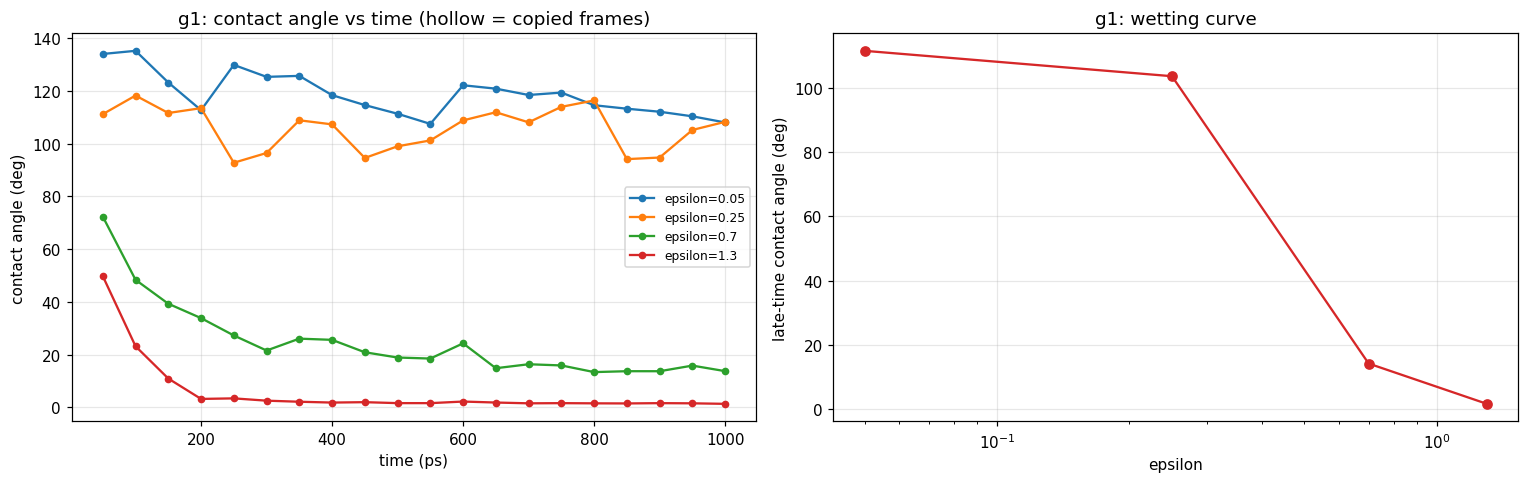

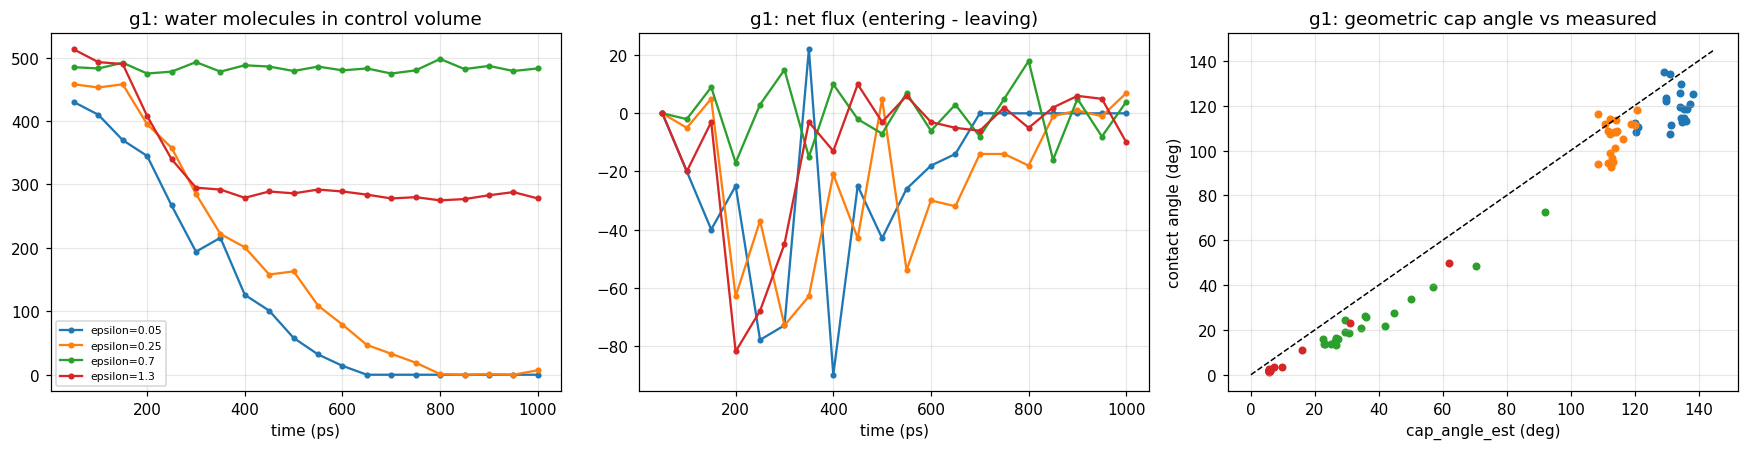

In [22]:
cmap_g1 = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, e in enumerate(EPS_LIST_g1):
    g = df_g1[df_g1["epsilon"] == e]
    ax[0].plot(g["time_ps"], g[TARGET], "-o", color=cmap_g1(i), ms=4, label=f"epsilon={e}")
    c = g[g["is_copied"]]
    ax[0].scatter(c["time_ps"], c[TARGET], facecolors="none", edgecolors="k", s=45, zorder=3)
ax[0].set_xlabel("time (ps)")
ax[0].set_ylabel("contact angle (deg)")
ax[0].set_title("g1: contact angle vs time (hollow = copied frames)")
ax[0].legend(fontsize=8)
eq_g1 = [df_g1[df_g1["epsilon"] == e].sort_values("time_ps").tail(5)[TARGET].mean() for e in EPS_LIST_g1]
ax[1].semilogx(EPS_LIST_g1, eq_g1, "-o", color="tab:red")
ax[1].set_xlabel("epsilon")
ax[1].set_ylabel("late-time contact angle (deg)")
ax[1].set_title("g1: wetting curve")
plt.tight_layout()
plt.show()

if USE_TRAJ_g1:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for i, e in enumerate(EPS_LIST_g1):
        g = df_g1[df_g1["epsilon"] == e]
        ax[0].plot(g["time_ps"], g["n_cv"], "-o", ms=3, color=cmap_g1(i), label=f"epsilon={e}")
        ax[1].plot(g["time_ps"], g["net_flux"], "-o", ms=3, color=cmap_g1(i))
        ax[2].scatter(g["cap_angle_est"], g[TARGET], color=cmap_g1(i), s=18)
    ax[0].set_title("g1: water molecules in control volume")
    ax[0].set_xlabel("time (ps)")
    ax[0].legend(fontsize=7)
    ax[1].set_title("g1: net flux (entering - leaving)")
    ax[1].set_xlabel("time (ps)")
    lim = [0, max(df_g1["cap_angle_est"].max(), df_g1[TARGET].max()) * 1.05]
    ax[2].plot(lim, lim, "k--", lw=1)
    ax[2].set_title("g1: geometric cap angle vs measured")
    ax[2].set_xlabel("cap_angle_est (deg)")
    ax[2].set_ylabel("contact angle (deg)")
    plt.tight_layout()
    plt.show()

## Models

In [23]:
def poly_ridge_g1(alpha, degree=3):
    nf = len(FEATURES_g1)
    base_idx = list(range(len(BASE_COLS)))
    rest_idx = list(range(len(BASE_COLS), nf))
    parts = [("poly", make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False)), base_idx)]
    if rest_idx:
        parts.append(("rest", StandardScaler(), rest_idx))
    return make_pipeline(ColumnTransformer(parts), Ridge(alpha=alpha))


def make_models_g1():
    models = {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Polynomial Ridge": poly_ridge_g1(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=500, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                                                       subsample=0.9, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.9,
                                colsample_bytree=0.9, reg_lambda=1.0, random_state=SEED, n_jobs=-1),
        "SVR": scaled_target(make_pipeline(StandardScaler(), SVR(C=20.0, epsilon=0.02, gamma="scale"))),
        "Gaussian Process": scaled_target(make_pipeline(StandardScaler(), GaussianProcessRegressor(
            kernel=ConstantKernel(1.0) * RBF(length_scale=2.0) + WhiteKernel(1e-3),
            n_restarts_optimizer=3, random_state=SEED))),
        "MLP (sklearn)": scaled_target(make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 64), activation="tanh", solver="lbfgs", alpha=1e-3,
            max_iter=5000, random_state=SEED))),
    }
    if HAS_TORCH:
        models["Neural Network (PyTorch)"] = TorchMLP()
        models["Physics-Constrained NN"] = PhysicsNN(cols=PHYS_COLS_g1)
    return models


MODELS_g1 = make_models_g1()
ENSEMBLE_MEMBERS_g1 = [m for m in ["XGBoost", "Gaussian Process", "SVR", "Extra Trees",
                                   "Neural Network (PyTorch)", "Physics-Constrained NN"] if m in MODELS_g1]
print(list(MODELS_g1))
print("ensemble members:", ENSEMBLE_MEMBERS_g1)


def run_protocol_g1(frame, splits, models):
    out = []
    for sid, (tr, te) in enumerate(splits):
        Xtr = frame.loc[tr, FEATURES_g1].values
        ytr = frame.loc[tr, TARGET].values
        Xte = frame.loc[te, FEATURES_g1].values
        for name, mdl in models.items():
            est = clone(mdl).fit(Xtr, ytr)
            pred = np.clip(est.predict(Xte), 0.0, 180.0)
            out.append(pd.DataFrame({
                "model": name, "split": sid,
                "epsilon": frame.loc[te, "epsilon"].values,
                "time_ps": frame.loc[te, "time_ps"].values,
                "y": frame.loc[te, TARGET].values, "pred": pred,
            }))
        print(f"g1 split {sid + 1}/{len(splits)} done")
    res = pd.concat(out, ignore_index=True)
    ens = (res[res["model"].isin(ENSEMBLE_MEMBERS_g1)]
           .groupby(["split", "epsilon", "time_ps", "y"], as_index=False)["pred"].mean())
    ens["model"] = "Ensemble (avg)"
    return pd.concat([res, ens], ignore_index=True)

['Linear Regression', 'Ridge', 'Polynomial Ridge', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost', 'SVR', 'Gaussian Process', 'MLP (sklearn)', 'Neural Network (PyTorch)', 'Physics-Constrained NN']
ensemble members: ['XGBoost', 'Gaussian Process', 'SVR', 'Extra Trees', 'Neural Network (PyTorch)', 'Physics-Constrained NN']


## g1 protocol A: temporal holdout (train t <= 750 ps, test t > 750 ps, real frames only)

In [24]:
real_mask_g1 = ~df_g1["is_copied"].values
tr_idx_g1 = np.where(df_g1["time_ps"].values <= TRAIN_TMAX_PS)[0]
te_idx_g1 = np.where((df_g1["time_ps"].values > TRAIN_TMAX_PS) & real_mask_g1)[0]
res_A_g1 = run_protocol_g1(df_g1, [(tr_idx_g1, te_idx_g1)], MODELS_g1)
table_A_g1 = score_table(res_A_g1)
print(f"train rows: {len(tr_idx_g1)} | test rows: {len(te_idx_g1)}")
display(table_A_g1.round(3))
table_A_g1.to_csv(os.path.join(OUT_DIR, "g1_metrics_temporal_holdout.csv"), index=False)
res_A_g1.to_csv(os.path.join(OUT_DIR, "g1_predictions_temporal_holdout.csv"), index=False)

g1 split 1/1 done
train rows: 60 | test rows: 20


,model,MAE,RMSE,R2,MaxAE
0,XGBoost,3.705,5.118,0.990,12.978
1,Extra Trees,3.359,5.719,0.987,16.877
2,Ensemble (avg),3.953,6.383,0.984,18.476
3,Linear Regression,6.374,7.099,0.980,13.633
4,Gaussian Process,4.795,7.255,0.979,20.288
5,Neural Network (PyTorch),4.761,7.316,0.979,19.562
6,Gradient Boosting,5.129,7.653,0.977,16.961
7,SVR,7.014,9.019,0.968,20.143
8,Polynomial Ridge,6.395,9.223,0.967,23.479
9,Random Forest,6.162,9.337,0.966,22.190


## g1 protocol B: leave-one-epsilon-out

In [25]:
splits_B_g1 = [(np.where(df_g1["epsilon"].values != e)[0],
                np.where((df_g1["epsilon"].values == e) & real_mask_g1)[0]) for e in EPS_LIST_g1]
res_B_g1 = run_protocol_g1(df_g1, splits_B_g1, MODELS_g1)
interior_g1 = EPS_LIST_g1[1:-1]
table_B_all_g1 = score_table(res_B_g1)
table_B_int_g1 = score_table(res_B_g1[res_B_g1["epsilon"].isin(interior_g1)])
print("pooled over all held-out epsilons (includes the two extrapolation ends)")
display(table_B_all_g1.round(3))
print(f"interior epsilons only {interior_g1}")
display(table_B_int_g1.round(3))
per_eps_g1 = (res_B_g1.assign(abs_err=(res_B_g1["y"] - res_B_g1["pred"]).abs())
              .pivot_table(index="model", columns="epsilon", values="abs_err", aggfunc="mean")
              .round(2))
print("MAE per held-out epsilon")
display(per_eps_g1)
table_B_all_g1.to_csv(os.path.join(OUT_DIR, "g1_metrics_leave_one_epsilon_out_all.csv"), index=False)
table_B_int_g1.to_csv(os.path.join(OUT_DIR, "g1_metrics_leave_one_epsilon_out_interior.csv"), index=False)
res_B_g1.to_csv(os.path.join(OUT_DIR, "g1_predictions_leave_one_epsilon_out.csv"), index=False)

g1 split 1/4 done
g1 split 2/4 done
g1 split 3/4 done
g1 split 4/4 done
pooled over all held-out epsilons (includes the two extrapolation ends)


,model,MAE,RMSE,R2,MaxAE
0,Random Forest,12.127,13.904,0.924,31.365
1,Gradient Boosting,11.963,14.013,0.922,31.485
2,Extra Trees,14.151,16.106,0.898,29.657
3,Ensemble (avg),14.912,17.576,0.878,37.041
4,Neural Network (PyTorch),16.755,20.407,0.836,44.807
5,Gaussian Process,20.243,23.226,0.787,42.919
6,Ridge,20.808,24.152,0.770,42.036
7,Physics-Constrained NN,21.918,27.558,0.700,56.877
8,Linear Regression,24.614,29.267,0.662,52.022
9,XGBoost,25.576,35.231,0.510,75.934


interior epsilons only [np.float64(0.25), np.float64(0.7)]


,model,MAE,RMSE,R2,MaxAE
0,Random Forest,9.236,10.566,0.937,19.423
1,Gradient Boosting,9.442,11.197,0.929,20.298
2,Extra Trees,15.640,18.196,0.813,29.657
3,Neural Network (PyTorch),17.004,18.312,0.811,33.043
4,Ensemble (avg),17.854,20.692,0.759,37.041
5,Gaussian Process,20.343,21.524,0.739,38.712
6,SVR,17.661,24.714,0.656,57.705
7,Ridge,24.682,25.744,0.627,37.039
8,Physics-Constrained NN,22.350,26.317,0.610,55.035
9,MLP (sklearn),24.974,29.932,0.495,66.289


MAE per held-out epsilon


epsilon,0.05,0.25,0.70,1.30
model,,,,
Ensemble (avg),8.33,10.28,25.43,15.61
Extra Trees,10.75,8.67,22.62,14.57
Gaussian Process,32.75,22.33,18.36,7.54
Gradient Boosting,12.66,5.58,13.30,16.31
Linear Regression,34.19,23.68,34.70,5.89
MLP (sklearn),56.24,14.01,35.94,8.83
Neural Network (PyTorch),28.95,18.46,15.55,4.07
Physics-Constrained NN,38.85,18.67,26.03,4.12
Polynomial Ridge,61.13,43.30,34.76,5.89


## g1 plots

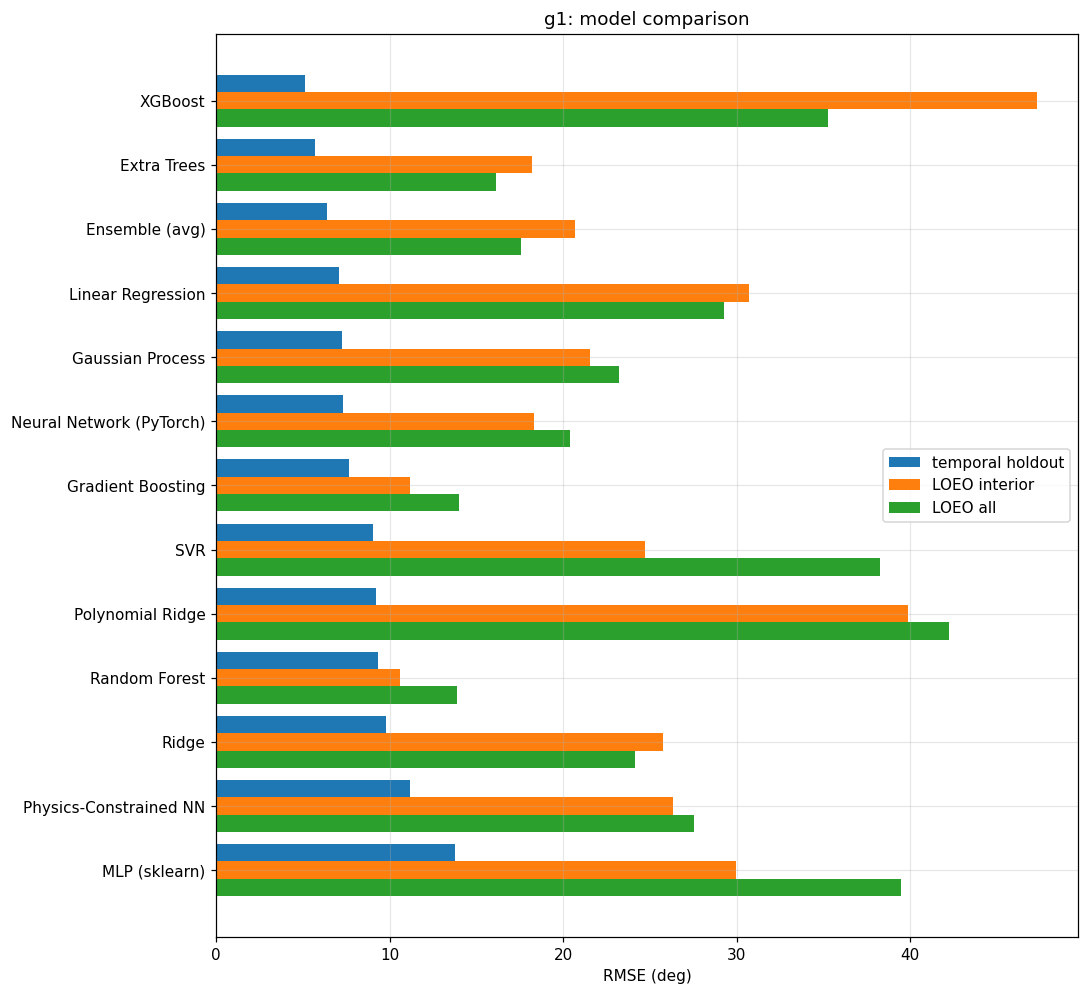

In [26]:
cmp_g1 = table_A_g1[["model", "RMSE"]].merge(table_B_int_g1[["model", "RMSE"]], on="model", suffixes=("_temporal", "_LOEO_interior"))
cmp_g1 = cmp_g1.merge(table_B_all_g1[["model", "RMSE"]].rename(columns={"RMSE": "RMSE_LOEO_all"}), on="model")
cmp_g1 = cmp_g1.sort_values("RMSE_temporal")
y = np.arange(len(cmp_g1))
fig, ax = plt.subplots(figsize=(10, 0.55 * len(cmp_g1) + 2))
ax.barh(y - 0.27, cmp_g1["RMSE_temporal"], 0.27, label="temporal holdout")
ax.barh(y, cmp_g1["RMSE_LOEO_interior"], 0.27, label="LOEO interior")
ax.barh(y + 0.27, cmp_g1["RMSE_LOEO_all"], 0.27, label="LOEO all")
ax.set_yticks(y)
ax.set_yticklabels(cmp_g1["model"])
ax.invert_yaxis()
ax.set_xlabel("RMSE (deg)")
ax.set_title("g1: model comparison")
ax.legend()
plt.tight_layout()
plt.show()

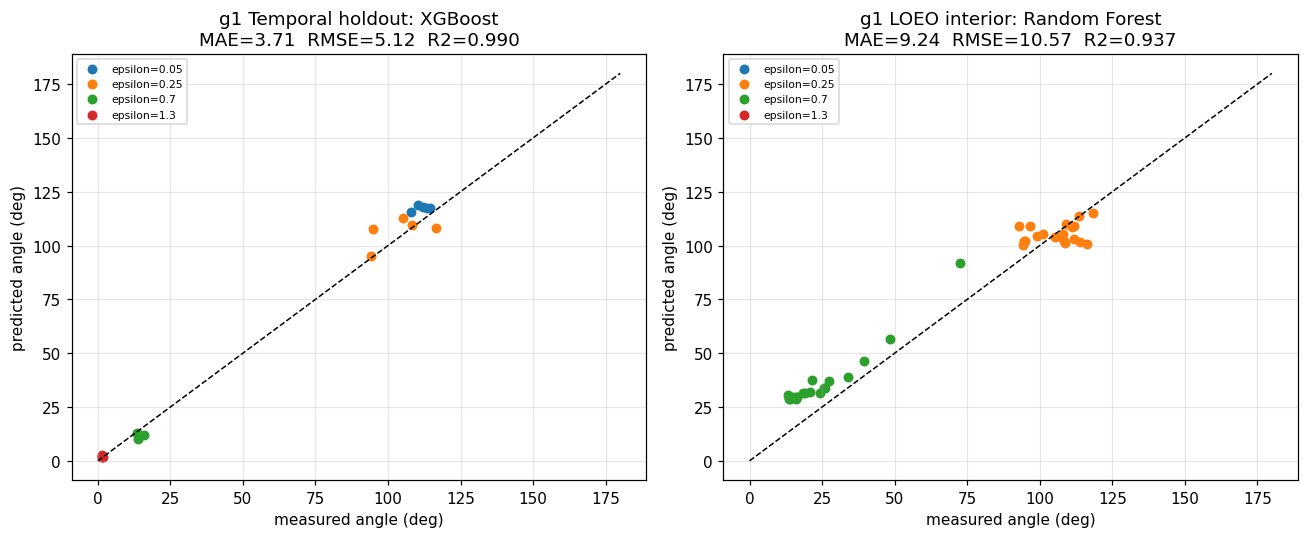

In [27]:
best_A_g1 = table_A_g1.iloc[0]["model"]
best_B_g1 = table_B_int_g1.iloc[0]["model"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, res, name, title in [(ax[0], res_A_g1, best_A_g1, "Temporal holdout"),
                            (ax[1], res_B_g1[res_B_g1["epsilon"].isin(interior_g1)], best_B_g1, "LOEO interior")]:
    g = res[res["model"] == name]
    for i, e in enumerate(EPS_LIST_g1):
        s = g[g["epsilon"] == e]
        a.scatter(s["y"], s["pred"], color=cmap_g1(i), s=30, label=f"epsilon={e}")
    lim = [0, 180]
    a.plot(lim, lim, "k--", lw=1)
    m = metrics(g["y"].values, g["pred"].values)
    a.set_title(f"g1 {title}: {name}\nMAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}  R2={m['R2']:.3f}")
    a.set_xlabel("measured angle (deg)")
    a.set_ylabel("predicted angle (deg)")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

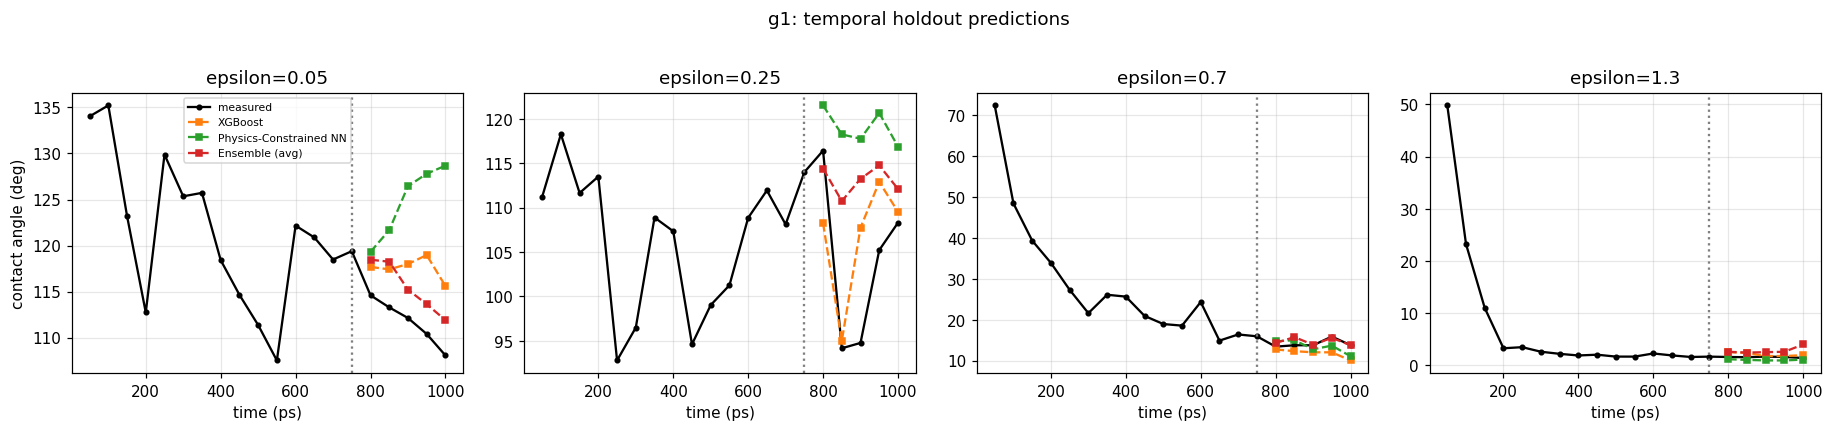

In [28]:
show_g1 = [best_A_g1]
for extra in ["Physics-Constrained NN", "Ensemble (avg)"]:
    if extra in set(res_A_g1["model"]) and extra not in show_g1:
        show_g1.append(extra)
eps_A_g1 = sorted(res_A_g1["epsilon"].unique())
fig, axes = plt.subplots(1, len(eps_A_g1), figsize=(4.2 * len(eps_A_g1), 3.8), sharey=False)
axes = np.atleast_1d(axes)
for a, e in zip(axes, eps_A_g1):
    g = df_g1[(df_g1["epsilon"] == e) & (~df_g1["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    a.axvline(TRAIN_TMAX_PS, color="gray", ls=":")
    for k, name in enumerate(show_g1):
        s = res_A_g1[(res_A_g1["model"] == name) & (res_A_g1["epsilon"] == e)].sort_values("time_ps")
        a.plot(s["time_ps"], s["pred"], "--s", ms=4, color=cmap_g1(k + 1), label=name)
    a.set_title(f"epsilon={e}")
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=7)
plt.suptitle("g1: temporal holdout predictions", y=1.02)
plt.tight_layout()
plt.show()

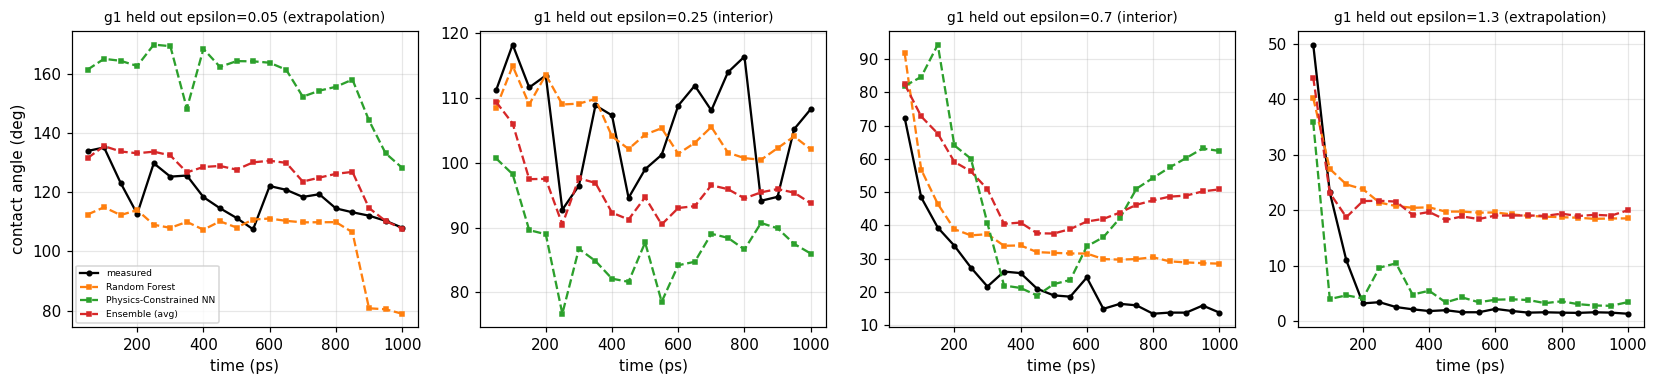

In [29]:
fig, axes = plt.subplots(1, len(EPS_LIST_g1), figsize=(3.8 * len(EPS_LIST_g1), 3.6))
for a, e in zip(axes, EPS_LIST_g1):
    g = df_g1[(df_g1["epsilon"] == e) & (~df_g1["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    for k, name in enumerate(dict.fromkeys([best_B_g1, "Physics-Constrained NN", "Ensemble (avg)"])):
        s = res_B_g1[(res_B_g1["model"] == name) & (res_B_g1["epsilon"] == e)].sort_values("time_ps")
        if len(s):
            a.plot(s["time_ps"], s["pred"], "--s", ms=3, color=cmap_g1(k + 1), label=name)
    tag = "interior" if e in interior_g1 else "extrapolation"
    a.set_title(f"g1 held out epsilon={e} ({tag})", fontsize=9)
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=6)
plt.tight_layout()
plt.show()

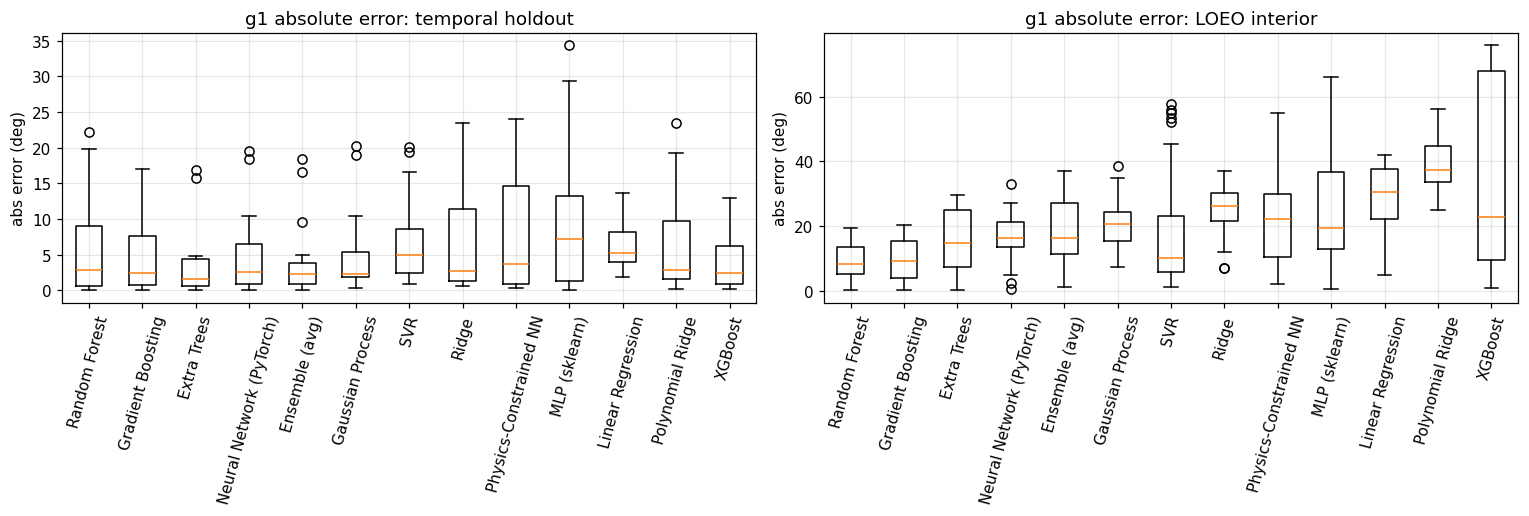

In [30]:
order_g1 = table_B_int_g1["model"].tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ea = res_A_g1.assign(err=(res_A_g1["y"] - res_A_g1["pred"]).abs())
eb = res_B_g1[res_B_g1["epsilon"].isin(interior_g1)]
eb = eb.assign(err=(eb["y"] - eb["pred"]).abs())
for a, e_df, title in [(ax[0], ea, "g1 absolute error: temporal holdout"), (ax[1], eb, "g1 absolute error: LOEO interior")]:
    names = [m for m in order_g1 if m in set(e_df["model"])]
    a.boxplot([e_df[e_df["model"] == m]["err"].values for m in names], showfliers=True)
    a.set_xticklabels(names)
    a.set_title(title)
    a.set_ylabel("abs error (deg)")
    a.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

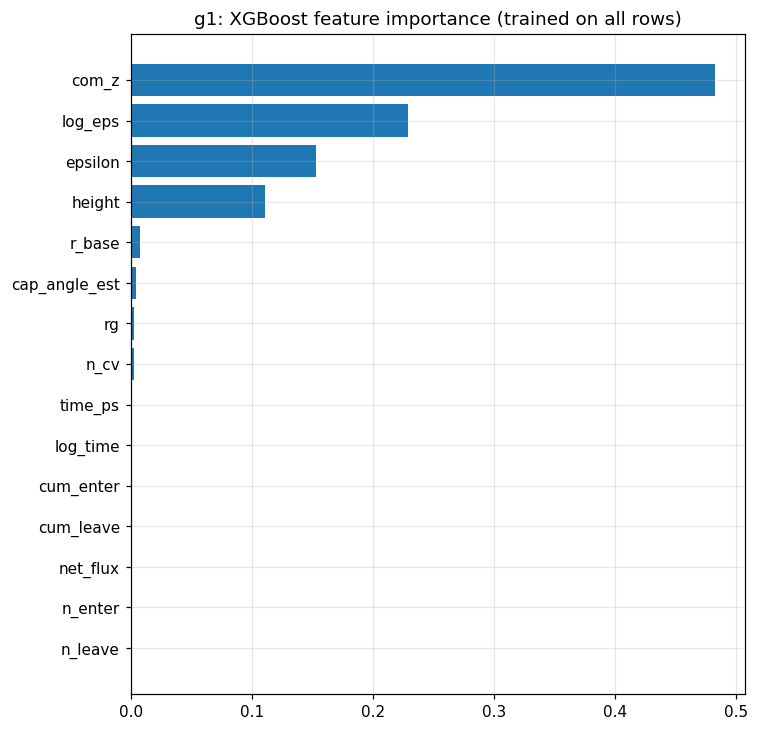

In [31]:
if USE_TRAJ_g1 and "XGBoost" in MODELS_g1:
    xgb_g1 = clone(MODELS_g1["XGBoost"]).fit(df_g1[FEATURES_g1].values, df_g1[TARGET].values)
    imp_g1 = pd.Series(xgb_g1.feature_importances_, index=FEATURES_g1).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp_g1) + 1.5))
    ax.barh(imp_g1.index, imp_g1.values, color="tab:blue")
    ax.set_title("g1: XGBoost feature importance (trained on all rows)")
    plt.tight_layout()
    plt.show()

## g1 final summary

In [32]:
final_g1 = pd.DataFrame({
    "temporal_RMSE": table_A_g1.set_index("model")["RMSE"],
    "temporal_R2": table_A_g1.set_index("model")["R2"],
    "LOEO_interior_RMSE": table_B_int_g1.set_index("model")["RMSE"],
    "LOEO_interior_R2": table_B_int_g1.set_index("model")["R2"],
    "LOEO_all_RMSE": table_B_all_g1.set_index("model")["RMSE"],
}).sort_values("temporal_RMSE")
display(final_g1.round(3))
final_g1.to_csv(os.path.join(OUT_DIR, "g1_final_summary.csv"))
print("features used:", FEATURES_g1)
print("trajectory features used:", USE_TRAJ_g1)
print("outputs saved to:", os.path.abspath(OUT_DIR))

,temporal_RMSE,temporal_R2,LOEO_interior_RMSE,LOEO_interior_R2,LOEO_all_RMSE
model,,,,,
XGBoost,5.118,0.990,47.299,-0.260,35.231
Extra Trees,5.719,0.987,18.196,0.813,16.106
Ensemble (avg),6.383,0.984,20.692,0.759,17.576
Linear Regression,7.099,0.980,30.704,0.469,29.267
Gaussian Process,7.255,0.979,21.524,0.739,23.226
Neural Network (PyTorch),7.316,0.979,18.312,0.811,20.407
Gradient Boosting,7.653,0.977,11.197,0.929,14.013
SVR,9.019,0.968,24.714,0.656,38.258
Polynomial Ridge,9.223,0.967,39.839,0.106,42.235


features used: ['epsilon', 'log_eps', 'time_ps', 'log_time', 'n_cv', 'n_enter', 'n_leave', 'net_flux', 'cum_enter', 'cum_leave', 'com_z', 'height', 'r_base', 'rg', 'cap_angle_est']
trajectory features used: True
outputs saved to: /content/outputs


# Dataset g3: three carbon planes (from the .gro files), epsilon 0.005, 0.05, 0.25, 0.7, 1.3

This section is independent of the dataset above: its own data, features, models and results, all with the suffix _g3. It reuses only generic helpers defined earlier (imports, constants, PyTorch classes, metrics, pick_index).

In [33]:
DATA_DIR_g3 = os.environ.get("DATA_DIR_g3", os.getcwd())


def count_xtc_g3():
    return len(glob.glob(os.path.join(DATA_DIR_g3, "*_3layer*.xtc")))


if IN_COLAB and count_xtc_g3() < 5:
    print("select the 5 xtc files (for example water_50ps_0.05_3layer.xtc) and the 5 frame0 gro files of this dataset")
    files.upload()

print("3layer xtc:", sorted(glob.glob(os.path.join(DATA_DIR_g3, "*_3layer*.xtc"))))
print("gro:", sorted(glob.glob(os.path.join(DATA_DIR_g3, "frame0_*.gro"))))

3layer xtc: ['/content/water_50ps_0.005_3layer.xtc', '/content/water_50ps_0.05_3layer.xtc', '/content/water_50ps_0.25_3layer.xtc', '/content/water_50ps_0.7_3layer.xtc', '/content/water_50ps_1.3_3layer.xtc']
gro: ['/content/frame0_0.005_3layer.gro', '/content/frame0_0.05.gro', '/content/frame0_0.05_3layer.gro', '/content/frame0_0.25.gro', '/content/frame0_0.25_3layer.gro', '/content/frame0_0.7.gro', '/content/frame0_0.7_3layer.gro', '/content/frame0_1.3.gro', '/content/frame0_1.3_3layer.gro']


## Load data

In [34]:
TIMES_g3 = np.arange(50, 1001, 50)
ANGLES_g3 = {
    0.005: [128.154, 132.082, 141.019, 108.157, 124.224, 117.710, 107.668, 108.147, 113.056, 113.793],
    0.05: [114.873, 110.372, 110.980, 133.218, 116.561, 113.495, 116.245, 108.010, 115.691, 120.370,
           117.589, 122.245, 114.161, 110.116, 117.730, 120.834, 117.382, 112.796, 114.374, 121.011],
    0.25: [99.202, 106.953, 110.336, 100.474, 102.401, 88.550, 83.033, 89.249, 87.680, 70.200,
           86.019, 80.532, 94.804, 82.734, 88.480, 76.107, 82.148, 79.681, 77.054, 80.741],
    0.7: [75.268, 52.564, 29.984, 22.984, 17.801, 16.586, 14.353, 11.089, 5.284, 4.129,
          7.797, 5.686, 6.843, 7.372, 6.604, 10.354, 7.131, 7.219, 4.839, 4.364],
    1.3: [51.934, 16.943, 7.460, 3.795, 1.529, 3.224, 1.778, 1.572, 2.209, 1.693,
          2.467, 2.335, 1.664, 1.976, 2.028, 2.382, 1.893, 1.603, 2.012, 1.682],
}
assert all(len(v) <= len(TIMES_g3) for v in ANGLES_g3.values())

rows_g3 = []
for e, vals in ANGLES_g3.items():
    tag = format(e, "g")
    for k, t in enumerate(TIMES_g3, start=1):
        available = k <= len(vals)
        rows_g3.append({
            "epsilon": e, "time_ps": float(t),
            "contact_angle_deg": vals[k - 1] if available else np.nan,
            "trajectory_file": f"water_50ps_{tag}_3layer.xtc",
            "trajectory_frame_number": float(k) if available else np.nan,
            "trajectory_frame_available": available,
        })
raw_g3 = pd.DataFrame(rows_g3).sort_values(["epsilon", "time_ps"]).reset_index(drop=True)
df_g3 = fill_missing_frames(raw_g3)
EPS_LIST_g3 = sorted(df_g3["epsilon"].unique())
summary_g3 = df_g3.groupby("epsilon").agg(
    total_frames=("time_ps", "size"),
    real_frames=("is_copied", lambda s: int((~s).sum())),
    copied_frames=("is_copied", "sum"),
)
display(summary_g3)


def read_gro_g3(path):
    with open(path) as f:
        lines = f.read().split("\n")
    n = int(lines[1])
    resn = []
    names = []
    xyz = []
    for ln in lines[2:2 + n]:
        resn.append(ln[5:10].strip())
        names.append(ln[10:15].strip())
        xyz.append([float(ln[20:28]), float(ln[28:36]), float(ln[36:44])])
    return np.array(resn), np.array(names), np.array(xyz)


def find_data_file_g3(eps, prefix, suffix, ext):
    tag = re.escape(format(float(eps), "g")).replace(r"\.", "[._]")
    pattern = re.compile(prefix + tag + suffix + r"(?: \(\d+\))?\." + ext + "$")
    for name in sorted(os.listdir(DATA_DIR_g3)):
        if pattern.search(name):
            return os.path.join(DATA_DIR_g3, name)
    raise FileNotFoundError(f"no {ext} file for epsilon={eps} in {DATA_DIR_g3}")


substrate_rows_g3 = []
for e in EPS_LIST_g3:
    try:
        resn, names, xyz0 = read_gro_g3(find_data_file_g3(e, "frame0_", "(?:_3layer)?", "gro"))
    except FileNotFoundError:
        continue
    sub = resn != "SOL"
    z = xyz0[sub, 2]
    substrate_rows_g3.append({
        "epsilon": e, "substrate_atoms": int(sub.sum()), "water_atoms": int((~sub).sum()),
        "substrate_planes": int(np.unique(np.round(z, 2)).size), "plane_z_nm": float(z.mean()),
    })
if substrate_rows_g3:
    display(pd.DataFrame(substrate_rows_g3))

,total_frames,real_frames,copied_frames
epsilon,,,
0.005,20,10,10
0.050,20,20,0
0.250,20,20,0
0.700,20,20,0
1.300,20,20,0


,epsilon,substrate_atoms,water_atoms,substrate_planes,plane_z_nm
0,0.005,29640,12465,3,4.058
1,0.050,9880,12465,1,18.409
2,0.250,9880,12465,1,18.409
3,0.700,9880,12465,1,18.409
4,1.300,9880,12465,1,18.409


## Trajectory features

In [35]:
def oxygen_index_g3(eps, n_atoms):
    try:
        resn, names, xyz0 = read_gro_g3(find_data_file_g3(eps, "frame0_", "(?:_3layer)?", "gro"))
    except FileNotFoundError:
        return np.arange(OXYGEN_OFFSET, n_atoms, OXYGEN_STRIDE)
    water = np.where(resn == "SOL")[0]
    if n_atoms == len(water):
        return np.where(names[water] == "OW")[0]
    if n_atoms == len(names):
        return np.where((resn == "SOL") & (names == "OW"))[0]
    return np.arange(OXYGEN_OFFSET, n_atoms, OXYGEN_STRIDE)


def load_oxygen_frames_g3(path, eps):
    from mdtraj.formats import XTCTrajectoryFile
    with XTCTrajectoryFile(path) as f:
        xyz, times, steps, box = f.read()
    ox = oxygen_index_g3(eps, xyz.shape[1])
    return xyz[:, ox, :].astype(np.float64), np.asarray(times, dtype=float)


def traj_features_for_eps_g3(eps, g):
    path = find_data_file_g3(eps, "water_50ps_", "_3layer", "xtc")
    oxy, times = load_oxygen_frames_g3(path, eps)
    real = g[~g["is_copied"]].sort_values("time_ps")
    idxs = [pick_index(times, t, fn) for t, fn in zip(real["time_ps"], real["trajectory_frame_number"])]
    frames = [oxy[i] for i in idxs]
    z_surf = np.percentile(frames[0][:, 2], 1)
    center = frames[0][:, :2].mean(axis=0)
    rows = []
    prev = None
    cum_in = 0
    cum_out = 0
    for fr in frames:
        d = np.linalg.norm(fr[:, :2] - center, axis=1)
        inside = (d <= CV_RADIUS_NM) & (fr[:, 2] >= z_surf) & (fr[:, 2] <= z_surf + CV_HEIGHT_NM)
        if prev is None:
            n_in = 0
            n_out = 0
        else:
            n_in = int((inside & ~prev).sum())
            n_out = int((~inside & prev).sum())
        cum_in += n_in
        cum_out += n_out
        prev = inside
        z = fr[:, 2] - z_surf
        com = fr.mean(axis=0)
        xy = np.linalg.norm(fr[:, :2] - com[:2], axis=1)
        base = z <= 0.5
        r_base = np.percentile(xy[base], 95) if base.sum() >= 3 else np.percentile(xy, 95)
        height = np.percentile(z, 99)
        rg = np.sqrt(((fr - com) ** 2).sum(axis=1).mean())
        rows.append({
            "n_cv": int(inside.sum()), "n_enter": n_in, "n_leave": n_out, "net_flux": n_in - n_out,
            "cum_enter": cum_in, "cum_leave": cum_out, "com_z": z.mean(), "height": height,
            "r_base": r_base, "rg": rg,
            "cap_angle_est": 2.0 * np.degrees(np.arctan2(height, max(r_base, 1e-6))),
        })
    return pd.DataFrame(rows)


def attach_traj_g3(frame):
    parts = []
    for eps, g in frame.groupby("epsilon", sort=True):
        g = g.sort_values("time_ps").reset_index(drop=True)
        tf = traj_features_for_eps_g3(eps, g)
        for c in TRAJ_COLS:
            g[c] = np.nan
        real_mask = ~g["is_copied"].values
        g.loc[real_mask, TRAJ_COLS] = tf[TRAJ_COLS].values
        last = tf[TRAJ_COLS].iloc[-1]
        for c in TRAJ_COLS:
            g.loc[g["is_copied"], c] = last[c]
        parts.append(g)
    return pd.concat(parts, ignore_index=True)


try:
    df_g3 = attach_traj_g3(df_g3)
    USE_TRAJ_g3 = True
    df_g3.to_csv(os.path.join(OUT_DIR, "g3_trajectory_features.csv"), index=False)
    print("trajectory features extracted from xtc files")
except Exception as exc:
    USE_TRAJ_g3 = False
    print("trajectory features unavailable, using epsilon and time only:", repr(exc))

trajectory features extracted from xtc files


## Feature engineering

In [37]:
df_g3["log_eps"] = np.log10(df_g3["epsilon"])
df_g3["log_time"] = np.log10(df_g3["time_ps"])

FEATURES_g3 = BASE_COLS + (TRAJ_COLS if USE_TRAJ_g3 else [])

PHYS_COLS_g3 = [
    FEATURES_g3.index("log_eps"),
    FEATURES_g3.index("time_ps")
] + [
    FEATURES_g3.index(c)
    for c in TRAJ_COLS if c in FEATURES_g3
]

print(len(df_g3), "rows |", len(FEATURES_g3), "features:", FEATURES_g3)

100 rows | 15 features: ['epsilon', 'log_eps', 'time_ps', 'log_time', 'n_cv', 'n_enter', 'n_leave', 'net_flux', 'cum_enter', 'cum_leave', 'com_z', 'height', 'r_base', 'rg', 'cap_angle_est']


## Data overview

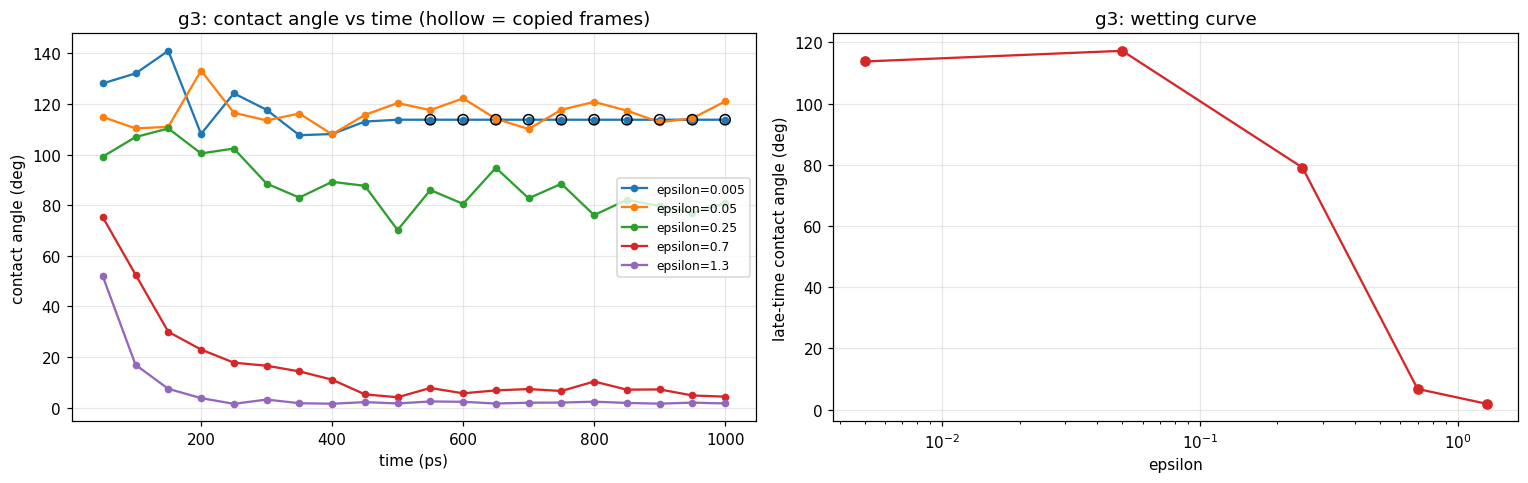

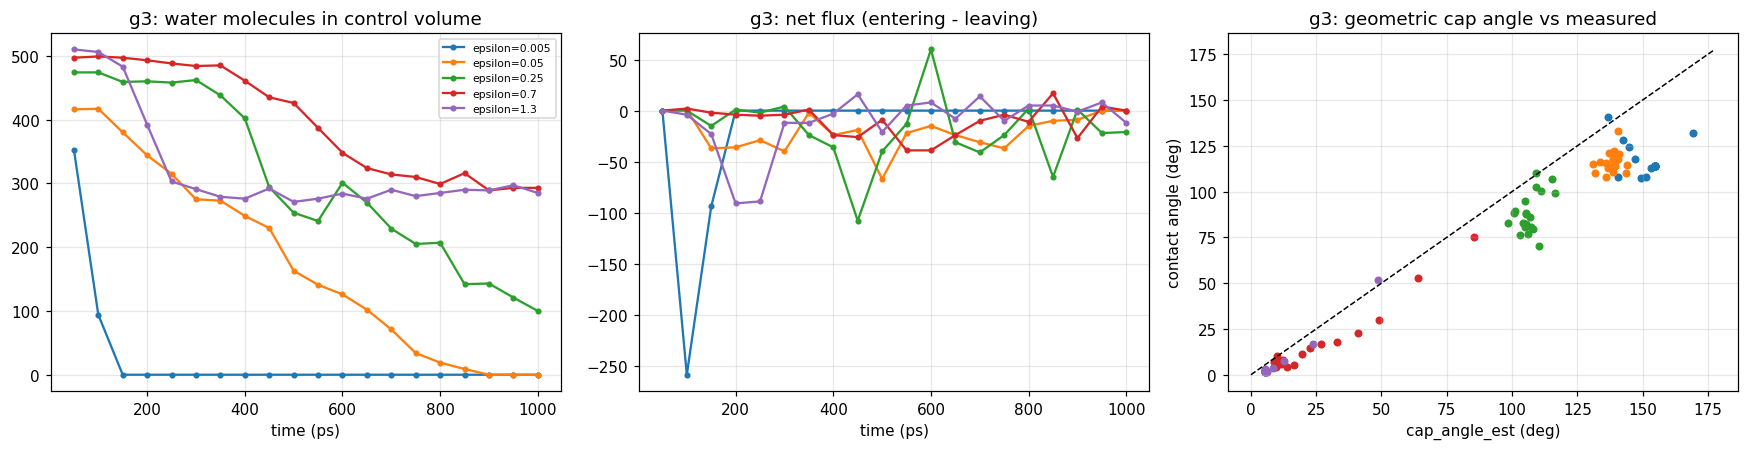

In [38]:
cmap_g3 = plt.get_cmap("tab10")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for i, e in enumerate(EPS_LIST_g3):
    g = df_g3[df_g3["epsilon"] == e]
    ax[0].plot(g["time_ps"], g[TARGET], "-o", color=cmap_g3(i), ms=4, label=f"epsilon={e}")
    c = g[g["is_copied"]]
    ax[0].scatter(c["time_ps"], c[TARGET], facecolors="none", edgecolors="k", s=45, zorder=3)
ax[0].set_xlabel("time (ps)")
ax[0].set_ylabel("contact angle (deg)")
ax[0].set_title("g3: contact angle vs time (hollow = copied frames)")
ax[0].legend(fontsize=8)
eq_g3 = [df_g3[df_g3["epsilon"] == e].sort_values("time_ps").tail(5)[TARGET].mean() for e in EPS_LIST_g3]
ax[1].semilogx(EPS_LIST_g3, eq_g3, "-o", color="tab:red")
ax[1].set_xlabel("epsilon")
ax[1].set_ylabel("late-time contact angle (deg)")
ax[1].set_title("g3: wetting curve")
plt.tight_layout()
plt.show()

if USE_TRAJ_g3:
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
    for i, e in enumerate(EPS_LIST_g3):
        g = df_g3[df_g3["epsilon"] == e]
        ax[0].plot(g["time_ps"], g["n_cv"], "-o", ms=3, color=cmap_g3(i), label=f"epsilon={e}")
        ax[1].plot(g["time_ps"], g["net_flux"], "-o", ms=3, color=cmap_g3(i))
        ax[2].scatter(g["cap_angle_est"], g[TARGET], color=cmap_g3(i), s=18)
    ax[0].set_title("g3: water molecules in control volume")
    ax[0].set_xlabel("time (ps)")
    ax[0].legend(fontsize=7)
    ax[1].set_title("g3: net flux (entering - leaving)")
    ax[1].set_xlabel("time (ps)")
    lim = [0, max(df_g3["cap_angle_est"].max(), df_g3[TARGET].max()) * 1.05]
    ax[2].plot(lim, lim, "k--", lw=1)
    ax[2].set_title("g3: geometric cap angle vs measured")
    ax[2].set_xlabel("cap_angle_est (deg)")
    ax[2].set_ylabel("contact angle (deg)")
    plt.tight_layout()
    plt.show()

## Models

In [39]:
def poly_ridge_g3(alpha, degree=3):
    nf = len(FEATURES_g3)
    base_idx = list(range(len(BASE_COLS)))
    rest_idx = list(range(len(BASE_COLS), nf))
    parts = [("poly", make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False)), base_idx)]
    if rest_idx:
        parts.append(("rest", StandardScaler(), rest_idx))
    return make_pipeline(ColumnTransformer(parts), Ridge(alpha=alpha))


def make_models_g3():
    models = {
        "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "Polynomial Ridge": poly_ridge_g3(alpha=1.0),
        "Random Forest": RandomForestRegressor(n_estimators=400, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Extra Trees": ExtraTreesRegressor(n_estimators=500, min_samples_leaf=1, random_state=SEED, n_jobs=-1),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=3,
                                                       subsample=0.9, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=500, learning_rate=0.05, max_depth=3, subsample=0.9,
                                colsample_bytree=0.9, reg_lambda=1.0, random_state=SEED, n_jobs=-1),
        "SVR": scaled_target(make_pipeline(StandardScaler(), SVR(C=20.0, epsilon=0.02, gamma="scale"))),
        "Gaussian Process": scaled_target(make_pipeline(StandardScaler(), GaussianProcessRegressor(
            kernel=ConstantKernel(1.0) * RBF(length_scale=2.0) + WhiteKernel(1e-3),
            n_restarts_optimizer=3, random_state=SEED))),
        "MLP (sklearn)": scaled_target(make_pipeline(StandardScaler(), MLPRegressor(
            hidden_layer_sizes=(64, 64), activation="tanh", solver="lbfgs", alpha=1e-3,
            max_iter=5000, random_state=SEED))),
    }
    if HAS_TORCH:
        models["Neural Network (PyTorch)"] = TorchMLP()
        models["Physics-Constrained NN"] = PhysicsNN(cols=PHYS_COLS_g3)
    return models


MODELS_g3 = make_models_g3()
ENSEMBLE_MEMBERS_g3 = [m for m in ["XGBoost", "Gaussian Process", "SVR", "Extra Trees",
                                   "Neural Network (PyTorch)", "Physics-Constrained NN"] if m in MODELS_g3]
print(list(MODELS_g3))
print("ensemble members:", ENSEMBLE_MEMBERS_g3)


def run_protocol_g3(frame, splits, models):
    out = []
    for sid, (tr, te) in enumerate(splits):
        Xtr = frame.loc[tr, FEATURES_g3].values
        ytr = frame.loc[tr, TARGET].values
        Xte = frame.loc[te, FEATURES_g3].values
        for name, mdl in models.items():
            est = clone(mdl).fit(Xtr, ytr)
            pred = np.clip(est.predict(Xte), 0.0, 180.0)
            out.append(pd.DataFrame({
                "model": name, "split": sid,
                "epsilon": frame.loc[te, "epsilon"].values,
                "time_ps": frame.loc[te, "time_ps"].values,
                "y": frame.loc[te, TARGET].values, "pred": pred,
            }))
        print(f"g3 split {sid + 1}/{len(splits)} done")
    res = pd.concat(out, ignore_index=True)
    ens = (res[res["model"].isin(ENSEMBLE_MEMBERS_g3)]
           .groupby(["split", "epsilon", "time_ps", "y"], as_index=False)["pred"].mean())
    ens["model"] = "Ensemble (avg)"
    return pd.concat([res, ens], ignore_index=True)

['Linear Regression', 'Ridge', 'Polynomial Ridge', 'Random Forest', 'Extra Trees', 'Gradient Boosting', 'XGBoost', 'SVR', 'Gaussian Process', 'MLP (sklearn)', 'Neural Network (PyTorch)', 'Physics-Constrained NN']
ensemble members: ['XGBoost', 'Gaussian Process', 'SVR', 'Extra Trees', 'Neural Network (PyTorch)', 'Physics-Constrained NN']


## g3 protocol A: temporal holdout (train t <= 750 ps, test t > 750 ps, real frames only)

In [40]:
real_mask_g3 = ~df_g3["is_copied"].values
tr_idx_g3 = np.where(df_g3["time_ps"].values <= TRAIN_TMAX_PS)[0]
te_idx_g3 = np.where((df_g3["time_ps"].values > TRAIN_TMAX_PS) & real_mask_g3)[0]
res_A_g3 = run_protocol_g3(df_g3, [(tr_idx_g3, te_idx_g3)], MODELS_g3)
table_A_g3 = score_table(res_A_g3)
print(f"train rows: {len(tr_idx_g3)} | test rows: {len(te_idx_g3)}")
display(table_A_g3.round(3))
table_A_g3.to_csv(os.path.join(OUT_DIR, "g3_metrics_temporal_holdout.csv"), index=False)
res_A_g3.to_csv(os.path.join(OUT_DIR, "g3_predictions_temporal_holdout.csv"), index=False)

g3 split 1/1 done
train rows: 75 | test rows: 20


,model,MAE,RMSE,R2,MaxAE
0,Ridge,3.491,4.275,0.992,9.052
1,Extra Trees,3.300,5.006,0.990,14.126
2,Random Forest,4.016,6.394,0.983,20.656
3,Physics-Constrained NN,4.332,6.439,0.983,16.140
4,Ensemble (avg),4.920,6.519,0.982,15.594
5,XGBoost,3.875,6.639,0.982,22.845
6,Polynomial Ridge,5.408,6.895,0.980,14.391
7,Linear Regression,6.251,7.373,0.977,14.101
8,Gradient Boosting,4.292,7.507,0.976,21.366
9,SVR,6.682,8.109,0.973,15.899


## g3 protocol B: leave-one-epsilon-out

In [41]:
splits_B_g3 = [(np.where(df_g3["epsilon"].values != e)[0],
                np.where((df_g3["epsilon"].values == e) & real_mask_g3)[0]) for e in EPS_LIST_g3]
res_B_g3 = run_protocol_g3(df_g3, splits_B_g3, MODELS_g3)
interior_g3 = EPS_LIST_g3[1:-1]
table_B_all_g3 = score_table(res_B_g3)
table_B_int_g3 = score_table(res_B_g3[res_B_g3["epsilon"].isin(interior_g3)])
print("pooled over all held-out epsilons (includes the two extrapolation ends)")
display(table_B_all_g3.round(3))
print(f"interior epsilons only {interior_g3}")
display(table_B_int_g3.round(3))
per_eps_g3 = (res_B_g3.assign(abs_err=(res_B_g3["y"] - res_B_g3["pred"]).abs())
              .pivot_table(index="model", columns="epsilon", values="abs_err", aggfunc="mean")
              .round(2))
print("MAE per held-out epsilon")
display(per_eps_g3)
table_B_all_g3.to_csv(os.path.join(OUT_DIR, "g3_metrics_leave_one_epsilon_out_all.csv"), index=False)
table_B_int_g3.to_csv(os.path.join(OUT_DIR, "g3_metrics_leave_one_epsilon_out_interior.csv"), index=False)
res_B_g3.to_csv(os.path.join(OUT_DIR, "g3_predictions_leave_one_epsilon_out.csv"), index=False)

g3 split 1/5 done
g3 split 2/5 done
g3 split 3/5 done
g3 split 4/5 done
g3 split 5/5 done
pooled over all held-out epsilons (includes the two extrapolation ends)


,model,MAE,RMSE,R2,MaxAE
0,Gradient Boosting,8.296,10.085,0.959,31.967
1,Random Forest,8.479,10.978,0.952,37.036
2,Extra Trees,12.475,15.498,0.904,34.183
3,Physics-Constrained NN,10.520,15.712,0.901,54.625
4,Ensemble (avg),13.460,16.742,0.888,38.225
5,Gaussian Process,13.251,17.046,0.884,40.808
6,MLP (sklearn),15.908,21.466,0.815,57.913
7,Ridge,13.565,21.887,0.808,72.332
8,Neural Network (PyTorch),19.695,25.469,0.740,65.864
9,Polynomial Ridge,20.179,28.398,0.677,95.937


interior epsilons only [np.float64(0.05), np.float64(0.25), np.float64(0.7)]


,model,MAE,RMSE,R2,MaxAE
0,Gradient Boosting,8.575,10.540,0.943,31.967
1,Random Forest,8.629,11.690,0.930,37.036
2,Ridge,10.599,13.432,0.907,31.832
3,Gaussian Process,13.599,16.230,0.864,40.198
4,Physics-Constrained NN,12.480,17.090,0.850,54.625
5,SVR,14.716,17.198,0.848,39.685
6,Extra Trees,14.864,17.873,0.836,34.183
7,Ensemble (avg),16.044,19.484,0.805,38.225
8,MLP (sklearn),18.558,23.667,0.712,57.913
9,Polynomial Ridge,20.411,25.538,0.664,50.823


MAE per held-out epsilon


epsilon,0.005,0.050,0.250,0.700,1.300
model,,,,,
Ensemble (avg),6.66,11.44,9.02,27.67,9.11
Extra Trees,8.43,10.08,8.61,25.90,7.33
Gaussian Process,29.46,13.97,10.79,16.04,4.10
Gradient Boosting,8.21,9.77,8.71,7.25,7.50
Linear Regression,54.40,64.27,15.85,31.44,17.73
MLP (sklearn),17.95,13.18,16.17,26.32,6.94
Neural Network (PyTorch),34.85,13.44,17.46,36.21,4.09
Physics-Constrained NN,14.73,12.03,16.99,8.42,2.54
Polynomial Ridge,47.92,11.39,10.04,39.81,5.61


## g3 plots

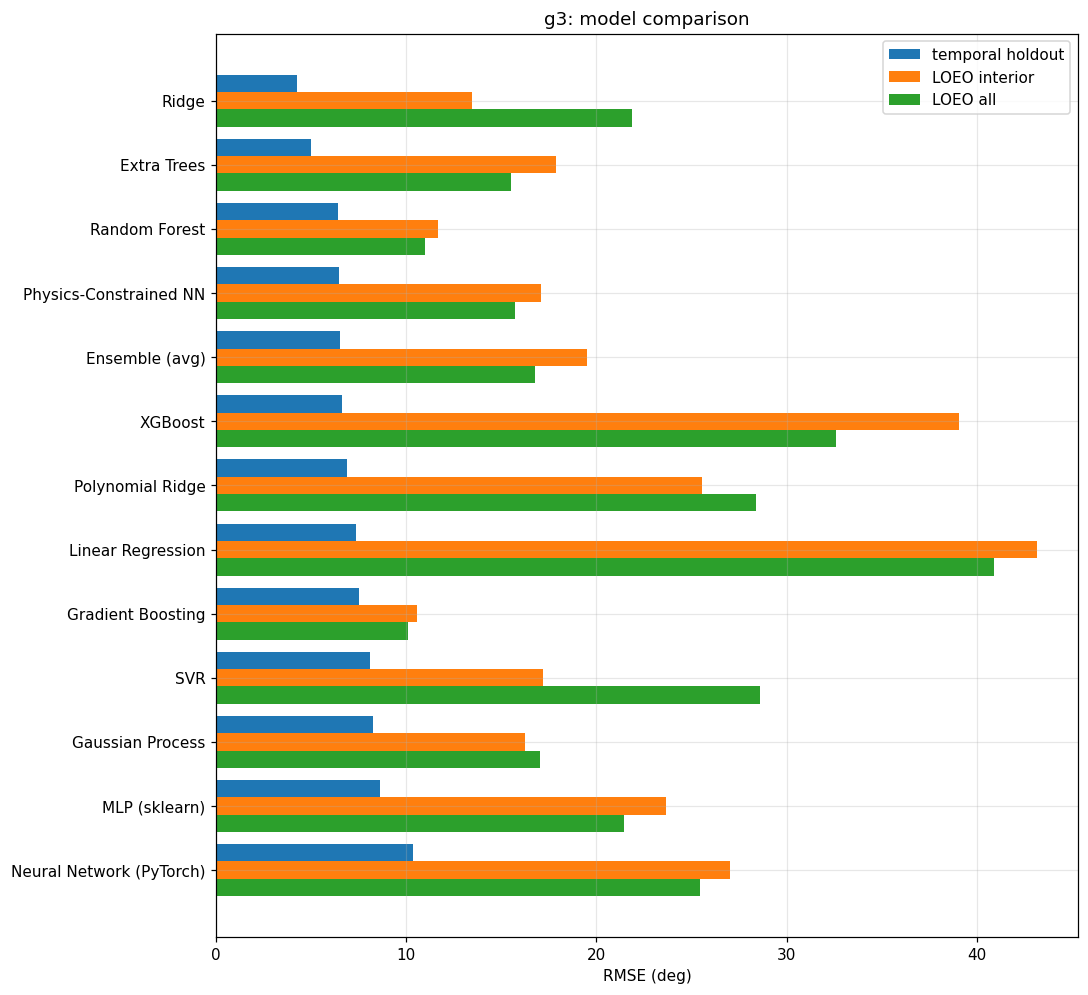

In [42]:
cmp_g3 = table_A_g3[["model", "RMSE"]].merge(table_B_int_g3[["model", "RMSE"]], on="model", suffixes=("_temporal", "_LOEO_interior"))
cmp_g3 = cmp_g3.merge(table_B_all_g3[["model", "RMSE"]].rename(columns={"RMSE": "RMSE_LOEO_all"}), on="model")
cmp_g3 = cmp_g3.sort_values("RMSE_temporal")
y = np.arange(len(cmp_g3))
fig, ax = plt.subplots(figsize=(10, 0.55 * len(cmp_g3) + 2))
ax.barh(y - 0.27, cmp_g3["RMSE_temporal"], 0.27, label="temporal holdout")
ax.barh(y, cmp_g3["RMSE_LOEO_interior"], 0.27, label="LOEO interior")
ax.barh(y + 0.27, cmp_g3["RMSE_LOEO_all"], 0.27, label="LOEO all")
ax.set_yticks(y)
ax.set_yticklabels(cmp_g3["model"])
ax.invert_yaxis()
ax.set_xlabel("RMSE (deg)")
ax.set_title("g3: model comparison")
ax.legend()
plt.tight_layout()
plt.show()

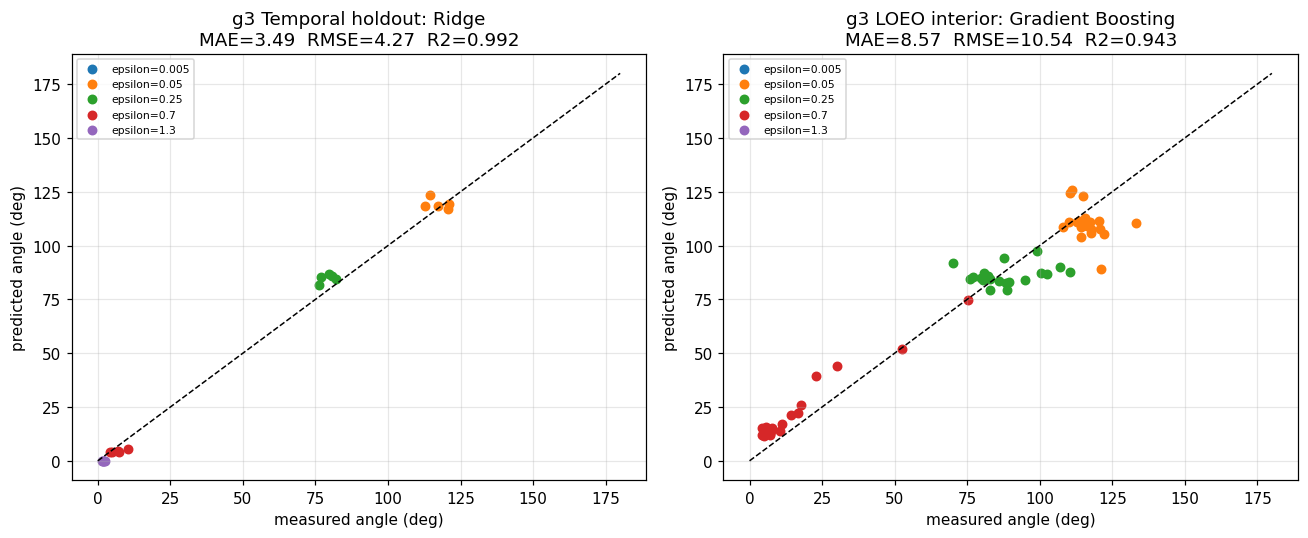

In [43]:
best_A_g3 = table_A_g3.iloc[0]["model"]
best_B_g3 = table_B_int_g3.iloc[0]["model"]
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
for a, res, name, title in [(ax[0], res_A_g3, best_A_g3, "Temporal holdout"),
                            (ax[1], res_B_g3[res_B_g3["epsilon"].isin(interior_g3)], best_B_g3, "LOEO interior")]:
    g = res[res["model"] == name]
    for i, e in enumerate(EPS_LIST_g3):
        s = g[g["epsilon"] == e]
        a.scatter(s["y"], s["pred"], color=cmap_g3(i), s=30, label=f"epsilon={e}")
    lim = [0, 180]
    a.plot(lim, lim, "k--", lw=1)
    m = metrics(g["y"].values, g["pred"].values)
    a.set_title(f"g3 {title}: {name}\nMAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}  R2={m['R2']:.3f}")
    a.set_xlabel("measured angle (deg)")
    a.set_ylabel("predicted angle (deg)")
    a.legend(fontsize=7)
plt.tight_layout()
plt.show()

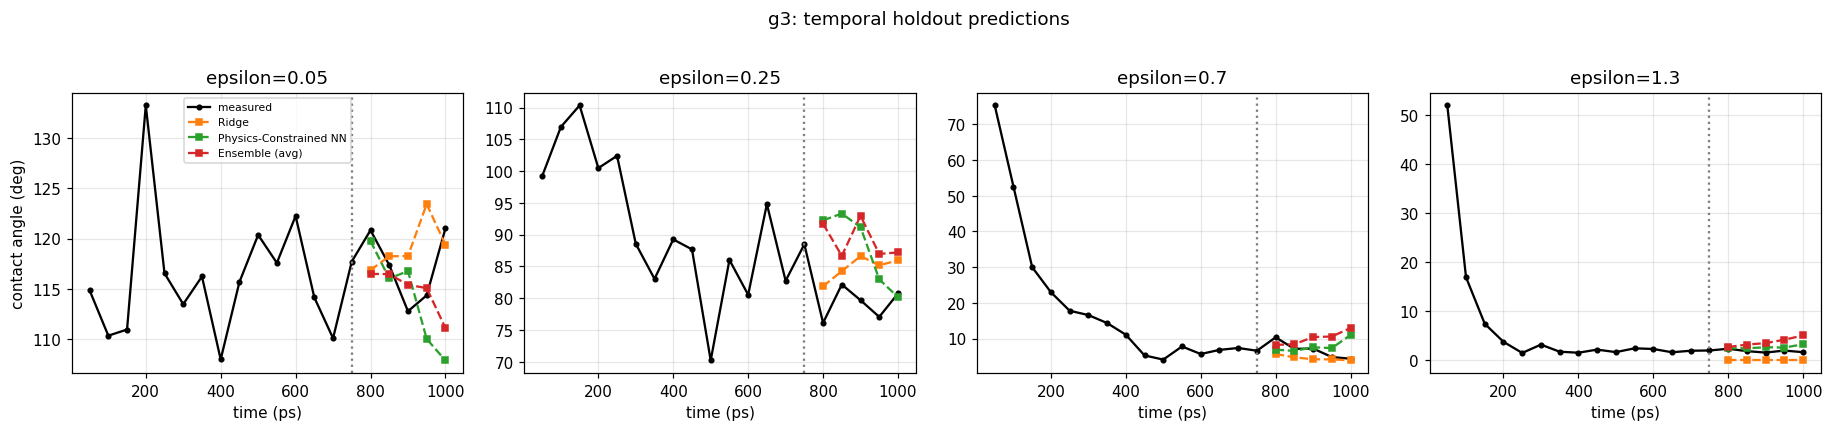

In [44]:
show_g3 = [best_A_g3]
for extra in ["Physics-Constrained NN", "Ensemble (avg)"]:
    if extra in set(res_A_g3["model"]) and extra not in show_g3:
        show_g3.append(extra)
eps_A_g3 = sorted(res_A_g3["epsilon"].unique())
fig, axes = plt.subplots(1, len(eps_A_g3), figsize=(4.2 * len(eps_A_g3), 3.8), sharey=False)
axes = np.atleast_1d(axes)
for a, e in zip(axes, eps_A_g3):
    g = df_g3[(df_g3["epsilon"] == e) & (~df_g3["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    a.axvline(TRAIN_TMAX_PS, color="gray", ls=":")
    for k, name in enumerate(show_g3):
        s = res_A_g3[(res_A_g3["model"] == name) & (res_A_g3["epsilon"] == e)].sort_values("time_ps")
        a.plot(s["time_ps"], s["pred"], "--s", ms=4, color=cmap_g3(k + 1), label=name)
    a.set_title(f"epsilon={e}")
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=7)
plt.suptitle("g3: temporal holdout predictions", y=1.02)
plt.tight_layout()
plt.show()

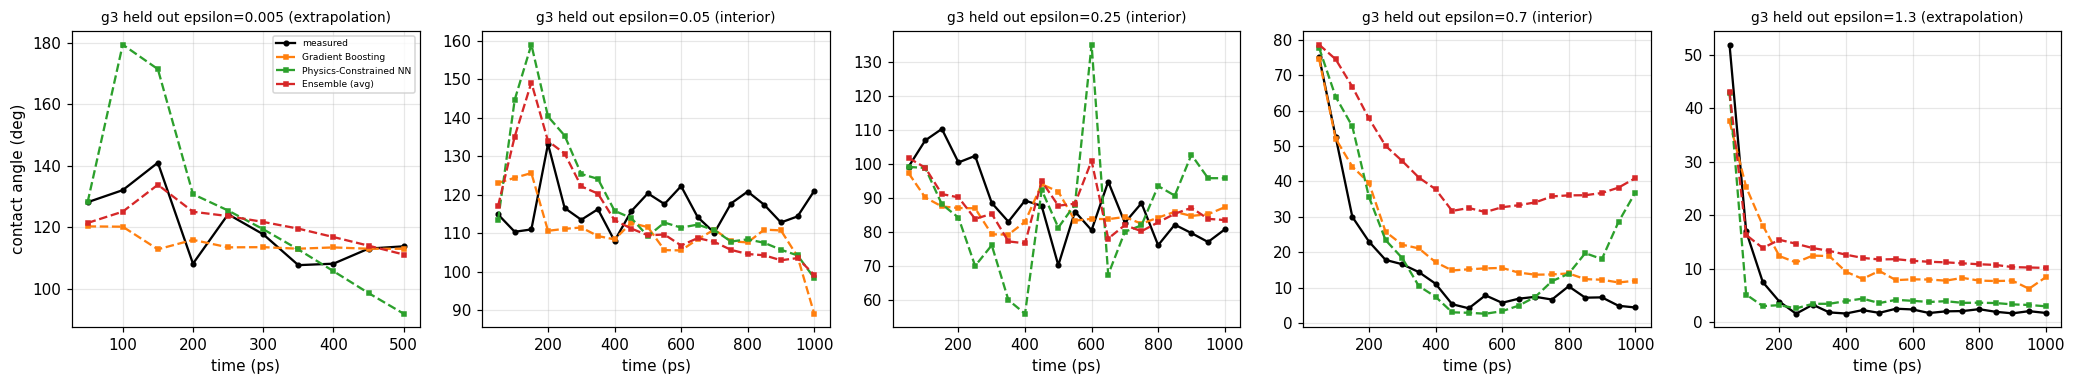

In [45]:
fig, axes = plt.subplots(1, len(EPS_LIST_g3), figsize=(3.8 * len(EPS_LIST_g3), 3.6))
for a, e in zip(axes, EPS_LIST_g3):
    g = df_g3[(df_g3["epsilon"] == e) & (~df_g3["is_copied"])]
    a.plot(g["time_ps"], g[TARGET], "k-o", ms=3, label="measured")
    for k, name in enumerate(dict.fromkeys([best_B_g3, "Physics-Constrained NN", "Ensemble (avg)"])):
        s = res_B_g3[(res_B_g3["model"] == name) & (res_B_g3["epsilon"] == e)].sort_values("time_ps")
        if len(s):
            a.plot(s["time_ps"], s["pred"], "--s", ms=3, color=cmap_g3(k + 1), label=name)
    tag = "interior" if e in interior_g3 else "extrapolation"
    a.set_title(f"g3 held out epsilon={e} ({tag})", fontsize=9)
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=6)
plt.tight_layout()
plt.show()

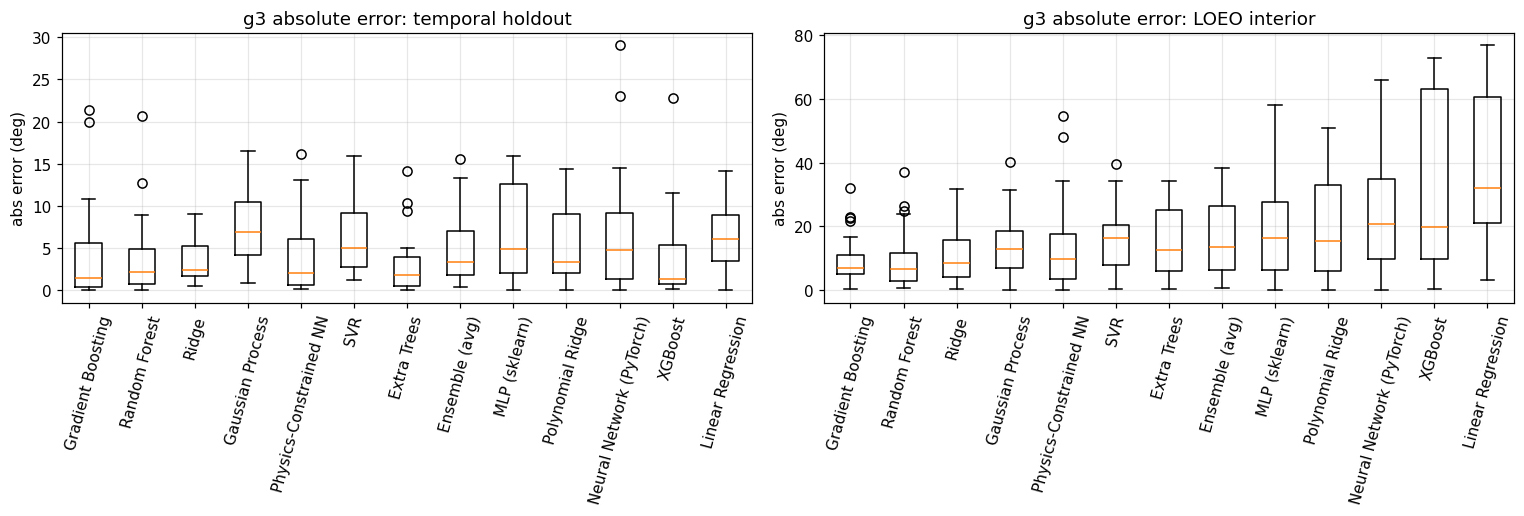

In [46]:
order_g3 = table_B_int_g3["model"].tolist()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ea = res_A_g3.assign(err=(res_A_g3["y"] - res_A_g3["pred"]).abs())
eb = res_B_g3[res_B_g3["epsilon"].isin(interior_g3)]
eb = eb.assign(err=(eb["y"] - eb["pred"]).abs())
for a, e_df, title in [(ax[0], ea, "g3 absolute error: temporal holdout"), (ax[1], eb, "g3 absolute error: LOEO interior")]:
    names = [m for m in order_g3 if m in set(e_df["model"])]
    a.boxplot([e_df[e_df["model"] == m]["err"].values for m in names], showfliers=True)
    a.set_xticklabels(names)
    a.set_title(title)
    a.set_ylabel("abs error (deg)")
    a.tick_params(axis="x", rotation=75)
plt.tight_layout()
plt.show()

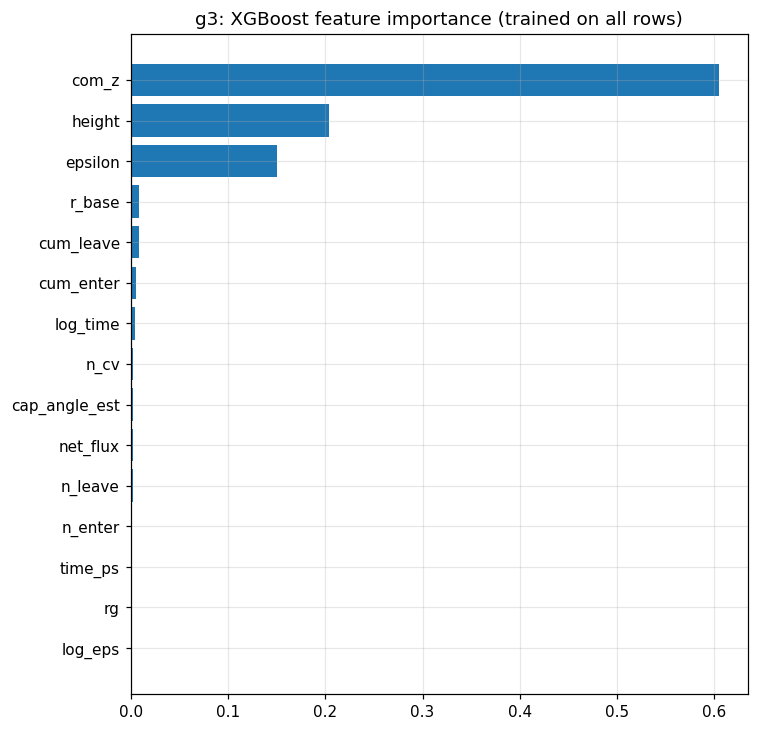

In [47]:
if USE_TRAJ_g3 and "XGBoost" in MODELS_g3:
    xgb_g3 = clone(MODELS_g3["XGBoost"]).fit(df_g3[FEATURES_g3].values, df_g3[TARGET].values)
    imp_g3 = pd.Series(xgb_g3.feature_importances_, index=FEATURES_g3).sort_values()
    fig, ax = plt.subplots(figsize=(7, 0.35 * len(imp_g3) + 1.5))
    ax.barh(imp_g3.index, imp_g3.values, color="tab:blue")
    ax.set_title("g3: XGBoost feature importance (trained on all rows)")
    plt.tight_layout()
    plt.show()

## g3 protocol C: interpolation holdout (predict in-between frames, neighbouring frames are in training)

In [48]:
N_FOLDS_INTERP = 4


def interpolation_splits(frame, n_folds=N_FOLDS_INTERP):
    fold_of = np.full(len(frame), -1)
    for eps, g in frame.groupby("epsilon"):
        real = g[~g["is_copied"]].sort_values("time_ps")
        inner = real.index.values[1:-1]
        for pos, idx in enumerate(inner):
            fold_of[idx] = pos % n_folds
    all_idx = np.arange(len(frame))
    splits = []
    for k in range(n_folds):
        te = np.where(fold_of == k)[0]
        tr = np.setdiff1d(all_idx, te)
        splits.append((tr, te))
    return splits


def plot_interpolation(res, frame, table, title):
    cm = plt.get_cmap("tab10")
    best = table.iloc[0]["model"]
    eps_all = sorted(res["epsilon"].unique())
    shown = [best] + [m for m in ["Physics-Constrained NN", "Ensemble (avg)"]
                      if m in set(res["model"]) and m != best]
    fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
    g = res[res["model"] == best]
    for i, e in enumerate(eps_all):
        s = g[g["epsilon"] == e]
        ax[0].scatter(s["y"], s["pred"], color=cm(i), s=28, label=f"epsilon={e}")
    ax[0].plot([0, 180], [0, 180], "k--", lw=1)
    m = metrics(g["y"].values, g["pred"].values)
    ax[0].set_title(f"{title} interpolation: {best}\nMAE={m['MAE']:.2f}  RMSE={m['RMSE']:.2f}  R2={m['R2']:.3f}")
    ax[0].set_xlabel("measured angle (deg)")
    ax[0].set_ylabel("predicted angle (deg)")
    ax[0].legend(fontsize=7)
    for k, name in enumerate(shown):
        s = res[res["model"] == name].copy()
        s["err"] = (s["y"] - s["pred"]).abs()
        by_t = s.groupby("time_ps")["err"].mean()
        ax[1].plot(by_t.index, by_t.values, "-o", ms=3, color=cm(k), label=name)
    ax[1].set_xlabel("time (ps)")
    ax[1].set_ylabel("mean abs error (deg)")
    ax[1].set_title(f"{title}: interpolation error vs time")
    ax[1].legend(fontsize=7)
    plt.tight_layout()
    plt.show()
    fig, axes = plt.subplots(1, len(eps_all), figsize=(3.8 * len(eps_all), 3.6))
    axes = np.atleast_1d(axes)
    for a, e in zip(axes, eps_all):
        gm = frame[(frame["epsilon"] == e) & (~frame["is_copied"])]
        a.plot(gm["time_ps"], gm[TARGET], "k-o", ms=3, label="measured")
        for k, name in enumerate(shown):
            s = res[(res["model"] == name) & (res["epsilon"] == e)].sort_values("time_ps")
            a.plot(s["time_ps"], s["pred"], "s", ms=4, color=cm(k + 1), label=name)
        a.set_title(f"{title} epsilon={e}", fontsize=9)
        a.set_xlabel("time (ps)")
    axes[0].set_ylabel("contact angle (deg)")
    axes[0].legend(fontsize=6)
    plt.tight_layout()
    plt.show()

g3 split 1/4 done
g3 split 2/4 done
g3 split 3/4 done
g3 split 4/4 done
g3 interpolation holdout: 80 test rows over 4 folds


,model,MAE,RMSE,R2,MaxAE
0,Extra Trees,4.420,6.877,0.981,27.133
1,Polynomial Ridge,4.675,7.206,0.979,26.959
2,Random Forest,4.754,7.660,0.977,37.755
3,Gradient Boosting,5.422,8.229,0.973,30.070
4,Ridge,5.636,8.419,0.972,33.174
5,XGBoost,5.241,8.442,0.972,34.883
6,Linear Regression,4.938,8.530,0.971,40.011
7,Ensemble (avg),5.432,9.058,0.968,45.662
8,Gaussian Process,5.719,9.590,0.964,50.276
9,SVR,6.526,11.062,0.952,65.537


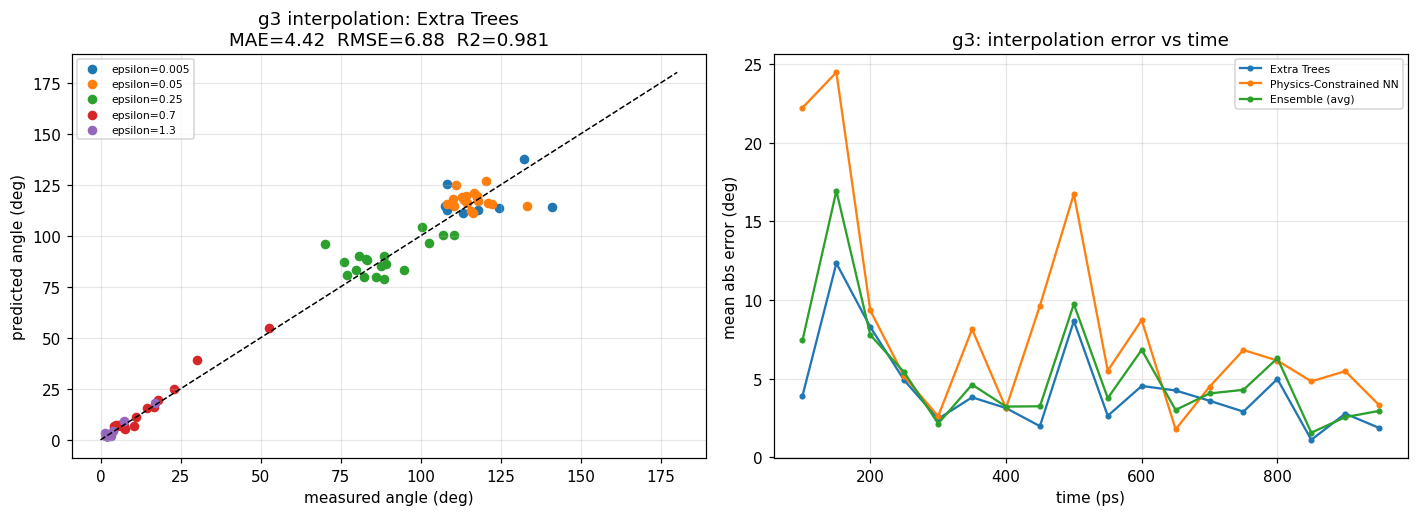

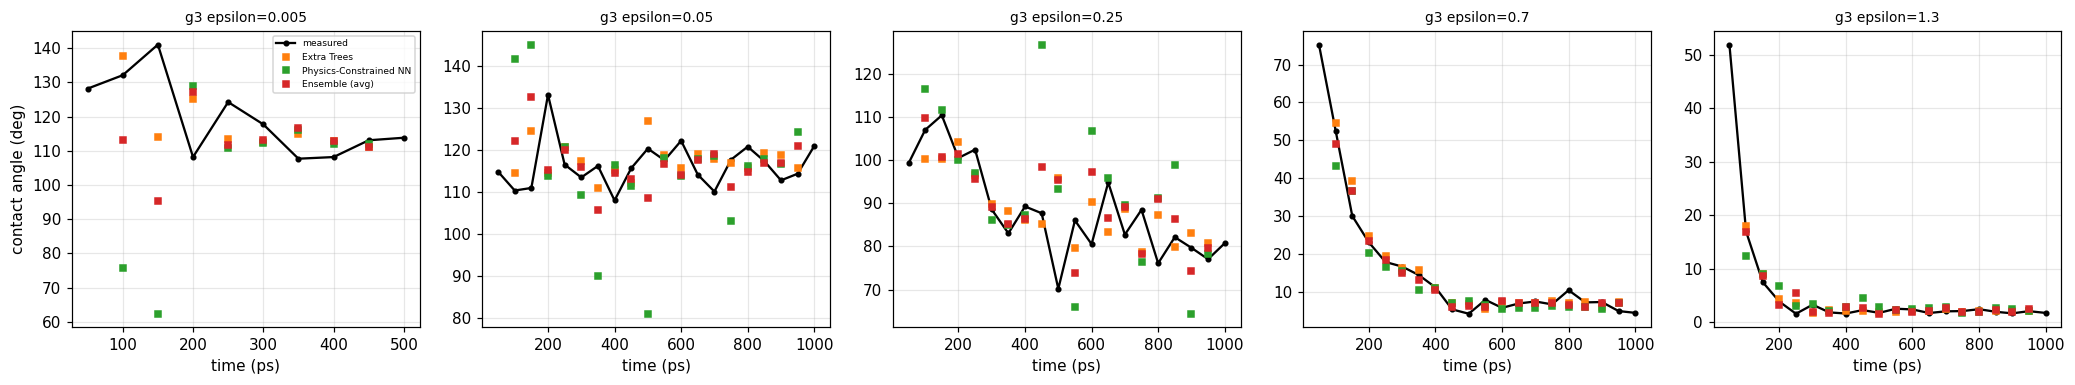

In [49]:
splits_C_g3 = interpolation_splits(df_g3)
res_C_g3 = run_protocol_g3(df_g3, splits_C_g3, MODELS_g3)
table_C_g3 = score_table(res_C_g3)
print(f"g3 interpolation holdout: {sum(len(te) for _, te in splits_C_g3)} test rows over {len(splits_C_g3)} folds")
display(table_C_g3.round(3))
table_C_g3.to_csv(os.path.join(OUT_DIR, "g3_metrics_interpolation_holdout.csv"), index=False)
res_C_g3.to_csv(os.path.join(OUT_DIR, "g3_predictions_interpolation_holdout.csv"), index=False)
plot_interpolation(res_C_g3, df_g3, table_C_g3, "g3")

## g3 final summary

In [50]:
final_g3 = pd.DataFrame({
    "temporal_RMSE": table_A_g3.set_index("model")["RMSE"],
    "temporal_R2": table_A_g3.set_index("model")["R2"],
    "LOEO_interior_RMSE": table_B_int_g3.set_index("model")["RMSE"],
    "LOEO_interior_R2": table_B_int_g3.set_index("model")["R2"],
    "LOEO_all_RMSE": table_B_all_g3.set_index("model")["RMSE"],
    "interp_RMSE": table_C_g3.set_index("model")["RMSE"],
    "interp_R2": table_C_g3.set_index("model")["R2"],
}).sort_values("temporal_RMSE")
display(final_g3.round(3))
final_g3.to_csv(os.path.join(OUT_DIR, "g3_final_summary.csv"))
print("features used:", FEATURES_g3)
print("trajectory features used:", USE_TRAJ_g3)
print("outputs saved to:", os.path.abspath(OUT_DIR))

,temporal_RMSE,temporal_R2,LOEO_interior_RMSE,LOEO_interior_R2,LOEO_all_RMSE,interp_RMSE,interp_R2
model,,,,,,,
Ridge,4.275,0.992,13.432,0.907,21.887,8.419,0.972
Extra Trees,5.006,0.990,17.873,0.836,15.498,6.877,0.981
Random Forest,6.394,0.983,11.690,0.930,10.978,7.660,0.977
Physics-Constrained NN,6.439,0.983,17.090,0.850,15.712,15.793,0.901
Ensemble (avg),6.519,0.982,19.484,0.805,16.742,9.058,0.968
XGBoost,6.639,0.982,39.087,0.214,32.608,8.442,0.972
Polynomial Ridge,6.895,0.980,25.538,0.664,28.398,7.206,0.979
Linear Regression,7.373,0.977,43.167,0.041,40.912,8.530,0.971
Gradient Boosting,7.507,0.976,10.540,0.943,10.085,8.229,0.973


features used: ['epsilon', 'log_eps', 'time_ps', 'log_time', 'n_cv', 'n_enter', 'n_leave', 'net_flux', 'cum_enter', 'cum_leave', 'com_z', 'height', 'r_base', 'rg', 'cap_angle_est']
trajectory features used: True
outputs saved to: /content/outputs


# Interpolation holdout for the first two datasets

Same in-between test as g3: frames strictly inside each trajectory are held out in 4 interleaved folds, and their neighbouring frames stay in training. The first and last real frame of every epsilon are never tested.

split 1/4 done
split 2/4 done
split 3/4 done
split 4/4 done
first dataset interpolation holdout: 72 test rows over 4 folds


,model,MAE,RMSE,R2,MaxAE
0,Extra Trees,2.767,4.112,0.993,14.342
1,Ensemble (avg),2.686,4.303,0.992,17.178
2,Gaussian Process,2.925,4.487,0.992,15.413
3,Random Forest,2.922,4.493,0.992,15.207
4,Physics-Constrained NN,3.357,4.524,0.992,14.227
5,Gradient Boosting,3.010,4.634,0.991,16.453
6,MLP (sklearn),3.166,4.842,0.990,13.934
7,Neural Network (PyTorch),3.020,4.898,0.990,21.634
8,XGBoost,3.099,5.107,0.989,17.082
9,SVR,3.360,5.219,0.989,20.570


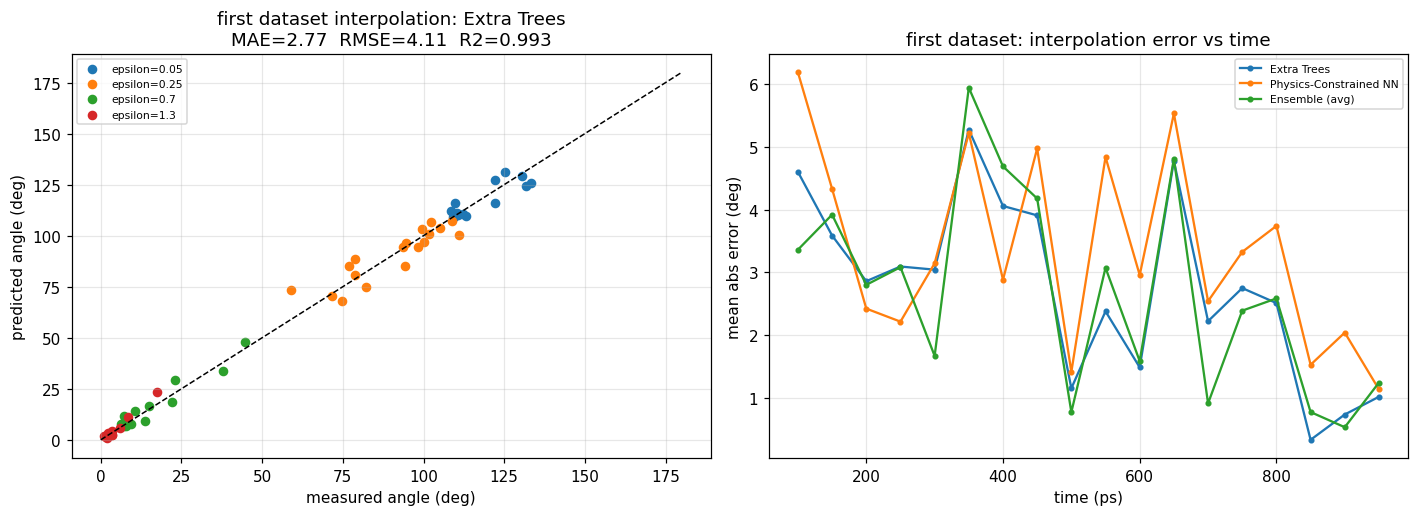

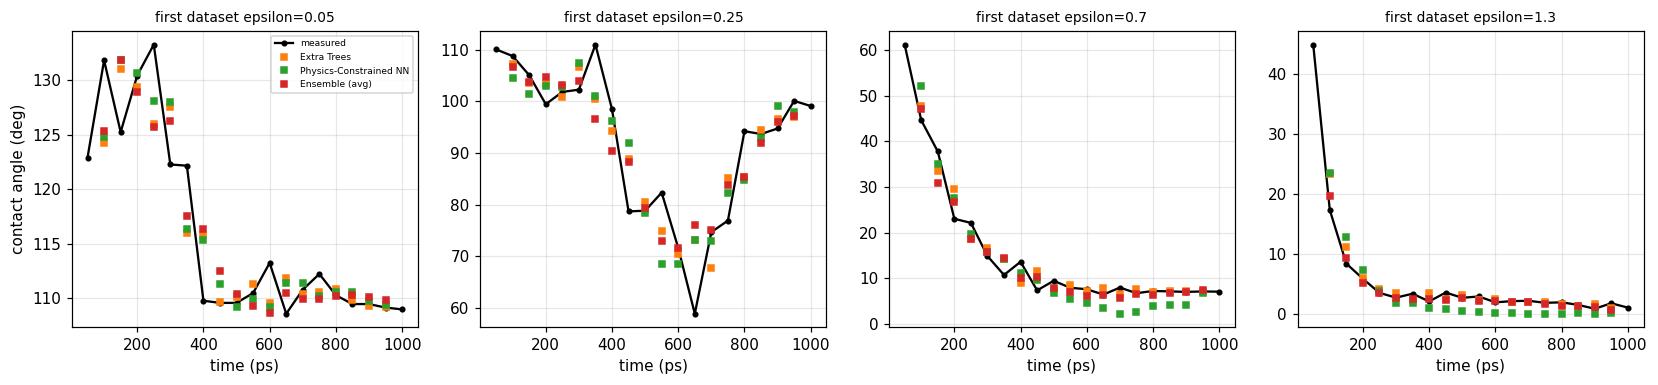

In [51]:
splits_C = interpolation_splits(df)
res_C = run_protocol(df, splits_C, MODELS)
table_C = score_table(res_C)
print(f"first dataset interpolation holdout: {sum(len(te) for _, te in splits_C)} test rows over {len(splits_C)} folds")
display(table_C.round(3))
table_C.to_csv(os.path.join(OUT_DIR, "metrics_interpolation_holdout.csv"), index=False)
res_C.to_csv(os.path.join(OUT_DIR, "predictions_interpolation_holdout.csv"), index=False)
plot_interpolation(res_C, df, table_C, "first dataset")

g1 split 1/4 done
g1 split 2/4 done
g1 split 3/4 done
g1 split 4/4 done
g1 interpolation holdout: 72 test rows over 4 folds


,model,MAE,RMSE,R2,MaxAE
0,Polynomial Ridge,4.176,5.752,0.987,16.115
1,Linear Regression,4.010,5.862,0.987,17.102
2,Ensemble (avg),4.177,5.929,0.986,15.187
3,Extra Trees,3.782,5.958,0.986,16.522
4,Gaussian Process,4.433,6.198,0.985,14.647
5,Random Forest,4.298,6.238,0.985,16.646
6,Gradient Boosting,4.225,6.450,0.984,19.554
7,XGBoost,4.479,6.692,0.983,20.176
8,Neural Network (PyTorch),4.984,6.864,0.982,18.531
9,Ridge,5.296,6.936,0.981,19.837


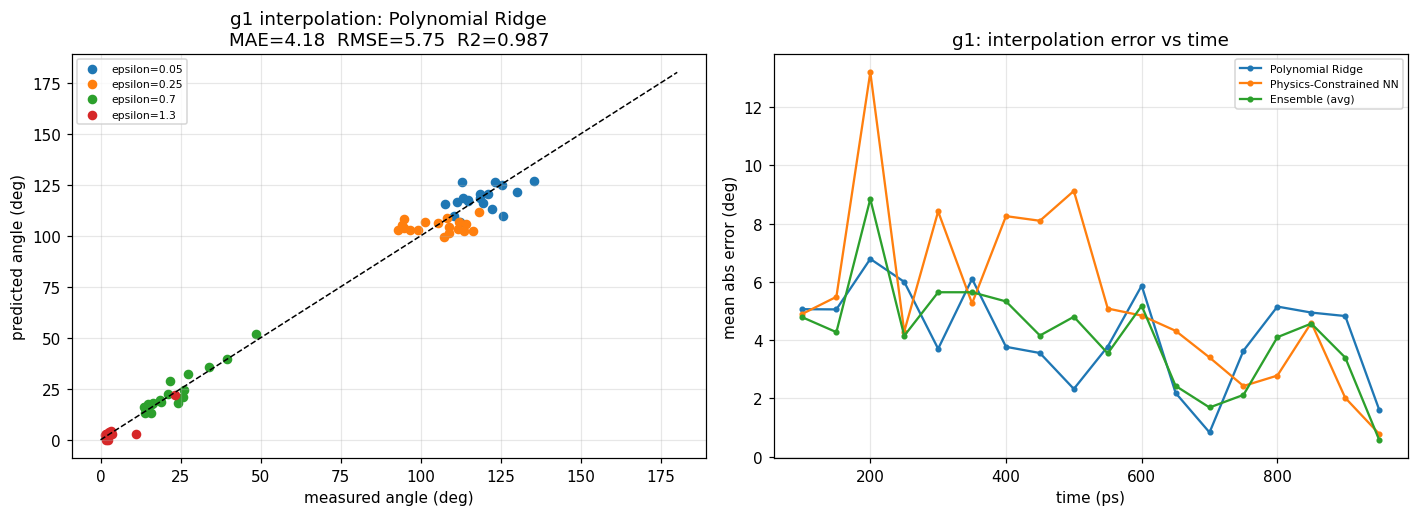

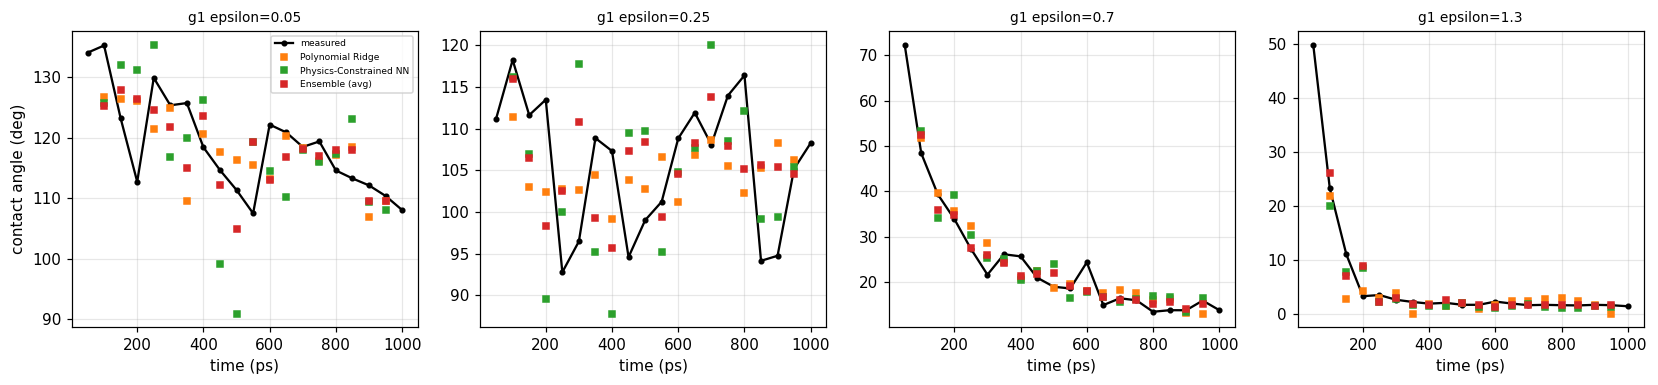

In [52]:
splits_C_g1 = interpolation_splits(df_g1)
res_C_g1 = run_protocol_g1(df_g1, splits_C_g1, MODELS_g1)
table_C_g1 = score_table(res_C_g1)
print(f"g1 interpolation holdout: {sum(len(te) for _, te in splits_C_g1)} test rows over {len(splits_C_g1)} folds")
display(table_C_g1.round(3))
table_C_g1.to_csv(os.path.join(OUT_DIR, "g1_metrics_interpolation_holdout.csv"), index=False)
res_C_g1.to_csv(os.path.join(OUT_DIR, "g1_predictions_interpolation_holdout.csv"), index=False)
plot_interpolation(res_C_g1, df_g1, table_C_g1, "g1")

# Comparison across the three datasets (1 layer = g1, 2 layer = first dataset, 3 layer = g3)

The 1-layer and 3-layer labels are confirmed by the .gro files (one and three carbon planes). The 2-layer label is taken from your description of the first dataset, since it has no .gro file to check.

In [53]:
LAYER_DATA = {"1 layer": df_g1, "2 layer": df, "3 layer": df_g3}
LAYER_COUNT = {"1 layer": 1, "2 layer": 2, "3 layer": 3}
LAYER_COLOR = {"1 layer": "tab:blue", "2 layer": "tab:orange", "3 layer": "tab:green"}
LATE_START_PS = 800
ALL_EPS = sorted(set().union(*[set(f["epsilon"].unique()) for f in LAYER_DATA.values()]))


def real_rows(frame, eps):
    return frame[(frame["epsilon"] == eps) & (~frame["is_copied"])].sort_values("time_ps")


def late_window(frame, eps):
    real = real_rows(frame, eps)
    late = real[real["time_ps"] >= LATE_START_PS]
    if len(late) >= 3:
        return late, True
    return real.tail(5), False


rows = []
for name, frame in LAYER_DATA.items():
    for e in sorted(frame["epsilon"].unique()):
        real = real_rows(frame, e)
        late, is_late = late_window(frame, e)
        rows.append({
            "layers": name, "epsilon": e, "real_frames": len(real),
            "first_angle": real[TARGET].iloc[0],
            "late_mean": late[TARGET].mean(),
            "late_std": late[TARGET].std(ddof=1) if len(late) >= 3 else np.nan,
            "window_ps": f"{late['time_ps'].min():.0f}-{late['time_ps'].max():.0f}",
            "is_late_window": is_late,
        })
summary_cmp = pd.DataFrame(rows)
display(summary_cmp.round(2))
summary_cmp.to_csv(os.path.join(OUT_DIR, "compare_layers_summary.csv"), index=False)

mean_tab = summary_cmp.pivot(index="epsilon", columns="layers", values="late_mean")
std_tab = summary_cmp.pivot(index="epsilon", columns="layers", values="late_std")
print("late-time mean angle (deg), frames from 800 ps where available")
display(mean_tab.round(1))
print("late-time frame-to-frame standard deviation (deg)")
display(std_tab.round(1))

,layers,epsilon,real_frames,first_angle,late_mean,late_std,window_ps,is_late_window
0,1 layer,0.05,20,134.03,111.69,2.55,800-1000,True
1,1 layer,0.25,20,111.21,103.77,9.43,800-1000,True
2,1 layer,0.70,20,72.37,14.12,1.00,800-1000,True
3,1 layer,1.30,20,49.80,1.55,0.10,800-1000,True
4,2 layer,0.00,2,134.18,135.91,NaN,50-100,False
5,2 layer,0.05,20,122.90,109.45,0.50,800-1000,True
6,2 layer,0.25,20,110.02,96.34,2.99,800-1000,True
7,2 layer,0.70,20,61.20,7.09,0.08,800-1000,True
8,2 layer,1.30,20,44.80,1.50,0.46,800-1000,True
9,3 layer,0.00,10,128.15,112.07,4.20,300-500,False


late-time mean angle (deg), frames from 800 ps where available


layers,1 layer,2 layer,3 layer
epsilon,,,
0.005,NaN,135.9,112.1
0.050,111.7,109.5,117.3
0.250,103.8,96.3,79.1
0.700,14.1,7.1,6.8
1.300,1.5,1.5,1.9


late-time frame-to-frame standard deviation (deg)


layers,1 layer,2 layer,3 layer
epsilon,,,
0.005,NaN,NaN,4.2
0.050,2.5,0.5,3.7
0.250,9.4,3.0,2.5
0.700,1.0,0.1,2.4
1.300,0.1,0.5,0.3


In [54]:
pairs = [("1 layer", "2 layer"), ("2 layer", "3 layer"), ("1 layer", "3 layer")]
rows = []
for e in ALL_EPS:
    for a, b in pairs:
        ra = summary_cmp[(summary_cmp["layers"] == a) & (summary_cmp["epsilon"] == e)]
        rb = summary_cmp[(summary_cmp["layers"] == b) & (summary_cmp["epsilon"] == e)]
        if ra.empty or rb.empty:
            continue
        ra = ra.iloc[0]
        rb = rb.iloc[0]
        comparable = bool(ra["is_late_window"]) and bool(rb["is_late_window"])
        delta = float(rb["late_mean"] - ra["late_mean"])
        noise = float(np.sqrt(np.nansum([ra["late_std"] ** 2, rb["late_std"] ** 2])))
        distinct = comparable and abs(delta) > 3.0 and abs(delta) > 2.0 * noise
        rows.append({
            "epsilon": e, "from": a, "to": b, "delta_deg": delta, "noise_deg": noise,
            "comparable_window": comparable, "distinguishable": distinct,
        })
pair_tab = pd.DataFrame(rows)
print("difference in late-time angle (to minus from); distinguishable = comparable window, |delta| > 3 deg and > 2x combined noise")
display(pair_tab.round(2))
pair_tab.to_csv(os.path.join(OUT_DIR, "compare_layers_pairwise.csv"), index=False)


def settle_time(frame, eps):
    real = real_rows(frame, eps)
    late, is_late = late_window(frame, eps)
    if not is_late:
        return np.nan
    final = late[TARGET].mean()
    tol = max(3.0, 2.0 * late[TARGET].std(ddof=1))
    inside = (real[TARGET] - final).abs().values <= tol
    for i in range(len(inside)):
        if inside[i:].all():
            return float(real["time_ps"].iloc[i])
    return np.nan


def relax_tau(frame, eps):
    from scipy.optimize import curve_fit
    real = real_rows(frame, eps)
    late, is_late = late_window(frame, eps)
    if not is_late or len(real) < 6:
        return np.nan
    t = real["time_ps"].values
    y = real[TARGET].values
    tail = y[-3:].mean()
    if abs(y[0] - tail) < 10.0:
        return np.nan

    def model(tt, a, b, tau):
        return a + b * np.exp(-tt / tau)

    try:
        popt, _ = curve_fit(model, t, y, p0=[tail, y[0] - tail, 200.0],
                            bounds=([-10.0, -400.0, 5.0], [200.0, 400.0, 3000.0]), maxfev=20000)
    except Exception:
        return np.nan
    return float(popt[2])


rows = []
for name, frame in LAYER_DATA.items():
    for e in sorted(frame["epsilon"].unique()):
        rows.append({"layers": name, "epsilon": e,
                     "settle_time_ps": settle_time(frame, e), "relax_tau_ps": relax_tau(frame, e)})
relax_tab = pd.DataFrame(rows)
print("settle_time_ps: first time after which every frame stays within max(3 deg, 2 std) of the late-time mean")
print("relax_tau_ps: exponential relaxation time, only where the angle changes by more than 10 deg")
display(relax_tab.pivot(index="epsilon", columns="layers", values="settle_time_ps").round(0))
display(relax_tab.pivot(index="epsilon", columns="layers", values="relax_tau_ps").round(0))
relax_tab.to_csv(os.path.join(OUT_DIR, "compare_layers_relaxation.csv"), index=False)


def crossing_epsilon(col):
    s = col.dropna().sort_index()
    le = np.log10(s.index.values.astype(float))
    y = s.values
    for i in range(len(y) - 1):
        if y[i] > 90.0 >= y[i + 1]:
            w = (y[i] - 90.0) / (y[i] - y[i + 1])
            return float(10 ** (le[i] + w * (le[i + 1] - le[i])))
    return np.nan


cross_tab = pd.Series({n: crossing_epsilon(mean_tab[n]) for n in LAYER_DATA}, name="epsilon_at_90deg")
print("epsilon where the late-time angle crosses 90 deg (log-linear interpolation between neighbouring epsilons)")
display(cross_tab.round(3).to_frame())
cross_tab.to_csv(os.path.join(OUT_DIR, "compare_layers_epsilon_at_90deg.csv"))

difference in late-time angle (to minus from); distinguishable = comparable window, |delta| > 3 deg and > 2x combined noise


,epsilon,from,to,delta_deg,noise_deg,comparable_window,distinguishable
0,0.00,2 layer,3 layer,-23.84,4.20,False,False
1,0.05,1 layer,2 layer,-2.24,2.60,True,False
2,0.05,2 layer,3 layer,7.82,3.75,True,True
3,0.05,1 layer,3 layer,5.59,4.50,True,False
4,0.25,1 layer,2 layer,-7.43,9.89,True,False
5,0.25,2 layer,3 layer,-17.19,3.91,True,True
6,0.25,1 layer,3 layer,-24.62,9.76,True,True
7,0.70,1 layer,2 layer,-7.02,1.00,True,True
8,0.70,2 layer,3 layer,-0.31,2.38,True,False
9,0.70,1 layer,3 layer,-7.34,2.58,True,True


settle_time_ps: first time after which every frame stays within max(3 deg, 2 std) of the late-time mean
relax_tau_ps: exponential relaxation time, only where the angle changes by more than 10 deg


layers,1 layer,2 layer,3 layer
epsilon,,,
0.005,NaN,NaN,NaN
0.050,800.0,650.0,450.0
0.250,50.0,800.0,800.0
0.700,650.0,450.0,400.0
1.300,200.0,250.0,200.0


layers,1 layer,2 layer,3 layer
epsilon,,,
0.005,NaN,NaN,NaN
0.050,338.0,496.0,NaN
0.250,NaN,220.0,361.0
0.700,134.0,142.0,109.0
1.300,59.0,51.0,43.0


epsilon where the late-time angle crosses 90 deg (log-linear interpolation between neighbouring epsilons)


,epsilon_at_90deg
1 layer,0.293
2 layer,0.269
3 layer,0.158


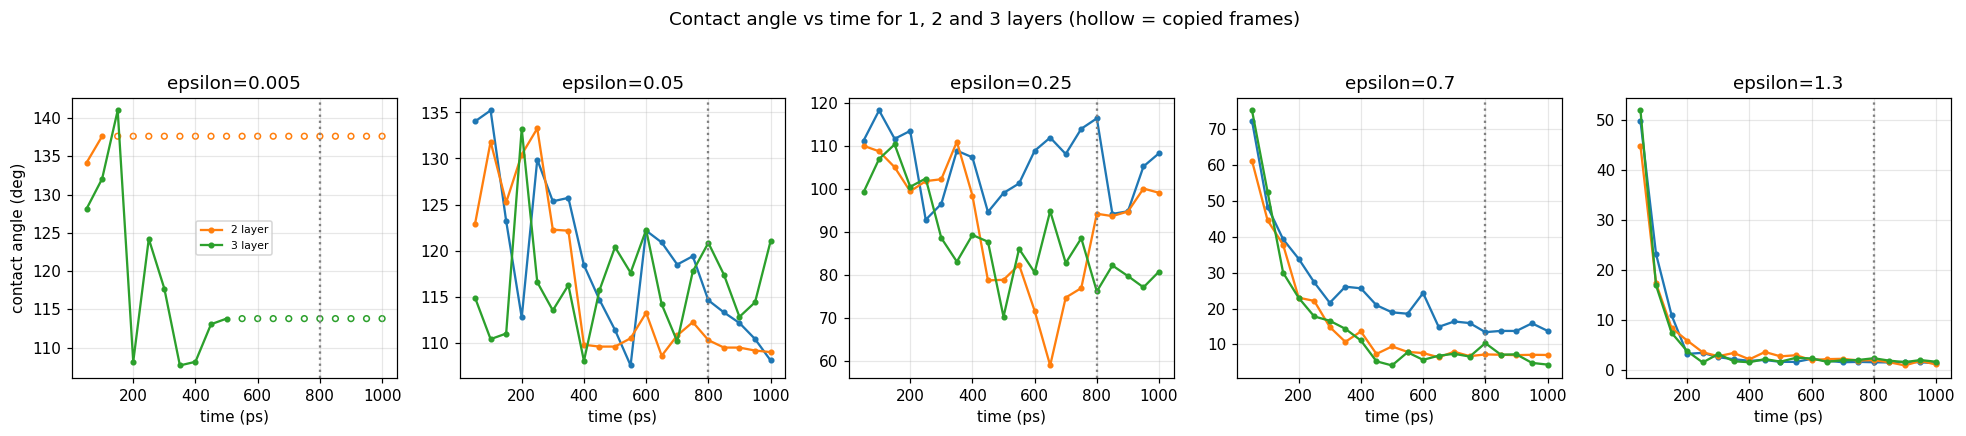

In [55]:
fig, axes = plt.subplots(1, len(ALL_EPS), figsize=(3.6 * len(ALL_EPS), 3.8), sharey=False)
axes = np.atleast_1d(axes)
for a, e in zip(axes, ALL_EPS):
    for name, frame in LAYER_DATA.items():
        sub = frame[frame["epsilon"] == e].sort_values("time_ps")
        if sub.empty:
            continue
        real = sub[~sub["is_copied"]]
        a.plot(real["time_ps"], real[TARGET], "-o", ms=3, color=LAYER_COLOR[name], label=name)
        cp = sub[sub["is_copied"]]
        if len(cp):
            a.scatter(cp["time_ps"], cp[TARGET], facecolors="none", edgecolors=LAYER_COLOR[name], s=14)
    a.axvline(LATE_START_PS, color="gray", ls=":")
    a.set_title(f"epsilon={e}")
    a.set_xlabel("time (ps)")
axes[0].set_ylabel("contact angle (deg)")
axes[0].legend(fontsize=7)
plt.suptitle("Contact angle vs time for 1, 2 and 3 layers (hollow = copied frames)", y=1.03)
plt.tight_layout()
plt.show()

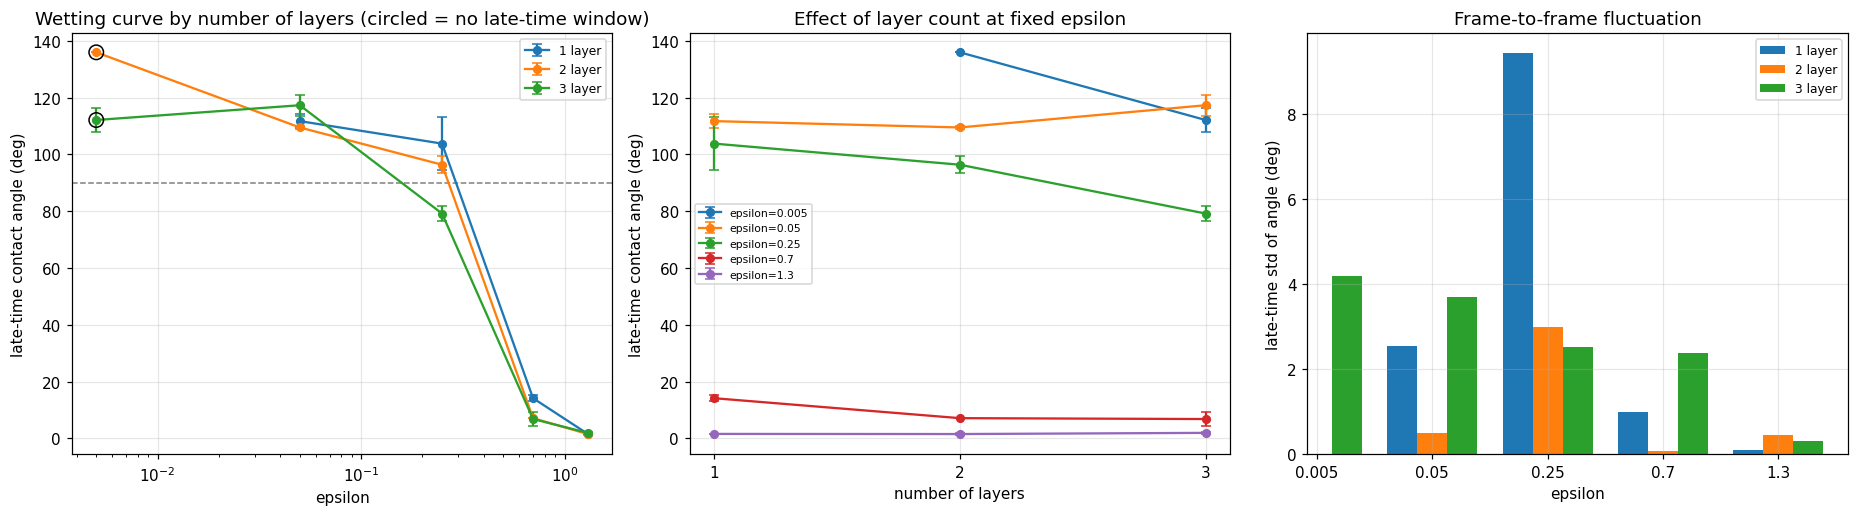

In [56]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
for name in LAYER_DATA:
    sub = summary_cmp[summary_cmp["layers"] == name].sort_values("epsilon")
    ax[0].errorbar(sub["epsilon"], sub["late_mean"], yerr=sub["late_std"].fillna(0.0), fmt="-o", ms=5,
                   capsize=3, color=LAYER_COLOR[name], label=name)
    weak = sub[~sub["is_late_window"]]
    ax[0].scatter(weak["epsilon"], weak["late_mean"], s=90, facecolors="none", edgecolors="k", zorder=4)
ax[0].set_xscale("log")
ax[0].axhline(90, color="gray", ls="--", lw=1)
ax[0].set_xlabel("epsilon")
ax[0].set_ylabel("late-time contact angle (deg)")
ax[0].set_title("Wetting curve by number of layers (circled = no late-time window)")
ax[0].legend(fontsize=8)

for i, e in enumerate(ALL_EPS):
    sub = summary_cmp[summary_cmp["epsilon"] == e].copy()
    sub["n"] = sub["layers"].map(LAYER_COUNT)
    sub = sub.sort_values("n")
    ax[1].errorbar(sub["n"], sub["late_mean"], yerr=sub["late_std"].fillna(0.0), fmt="-o", ms=5, capsize=3,
                   color=plt.get_cmap("tab10")(i), label=f"epsilon={e}")
ax[1].set_xticks([1, 2, 3])
ax[1].set_xlabel("number of layers")
ax[1].set_ylabel("late-time contact angle (deg)")
ax[1].set_title("Effect of layer count at fixed epsilon")
ax[1].legend(fontsize=7)

width = 0.26
xs = np.arange(len(ALL_EPS))
for j, name in enumerate(LAYER_DATA):
    vals = [std_tab.loc[e, name] if e in std_tab.index and name in std_tab.columns else np.nan for e in ALL_EPS]
    ax[2].bar(xs + (j - 1) * width, vals, width, color=LAYER_COLOR[name], label=name)
ax[2].set_xticks(xs)
ax[2].set_xticklabels([str(e) for e in ALL_EPS])
ax[2].set_xlabel("epsilon")
ax[2].set_ylabel("late-time std of angle (deg)")
ax[2].set_title("Frame-to-frame fluctuation")
ax[2].legend(fontsize=8)
plt.tight_layout()
plt.show()

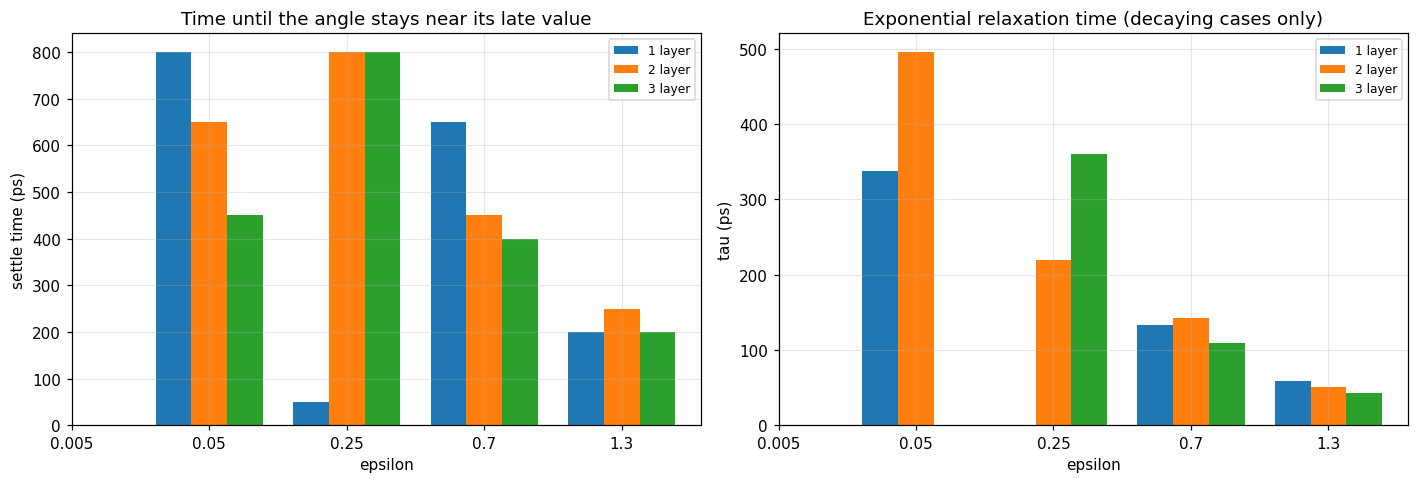

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for j, name in enumerate(LAYER_DATA):
    sub = relax_tab[relax_tab["layers"] == name].set_index("epsilon")
    st = [sub["settle_time_ps"].get(e, np.nan) for e in ALL_EPS]
    tau = [sub["relax_tau_ps"].get(e, np.nan) for e in ALL_EPS]
    ax[0].bar(xs + (j - 1) * width, st, width, color=LAYER_COLOR[name], label=name)
    ax[1].bar(xs + (j - 1) * width, tau, width, color=LAYER_COLOR[name], label=name)
for a, title, yl in [(ax[0], "Time until the angle stays near its late value", "settle time (ps)"),
                     (ax[1], "Exponential relaxation time (decaying cases only)", "tau (ps)")]:
    a.set_xticks(xs)
    a.set_xticklabels([str(e) for e in ALL_EPS])
    a.set_xlabel("epsilon")
    a.set_ylabel(yl)
    a.set_title(title)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

,layers,epsilon,r_base,height,rg,cap_bias
0,1 layer,0.05,2.62,5.20,3.45,15.00
1,1 layer,0.25,2.99,4.44,2.49,8.30
2,1 layer,0.70,6.11,1.30,4.01,9.90
3,1 layer,1.30,9.62,0.49,6.28,4.25
4,3 layer,0.00,2.85,11.20,2.37,39.14
5,3 layer,0.05,1.99,5.34,2.49,21.79
6,3 layer,0.25,3.13,4.16,2.45,26.89
7,3 layer,0.70,7.57,0.63,5.31,2.80
8,3 layer,1.30,9.65,0.47,6.29,3.65


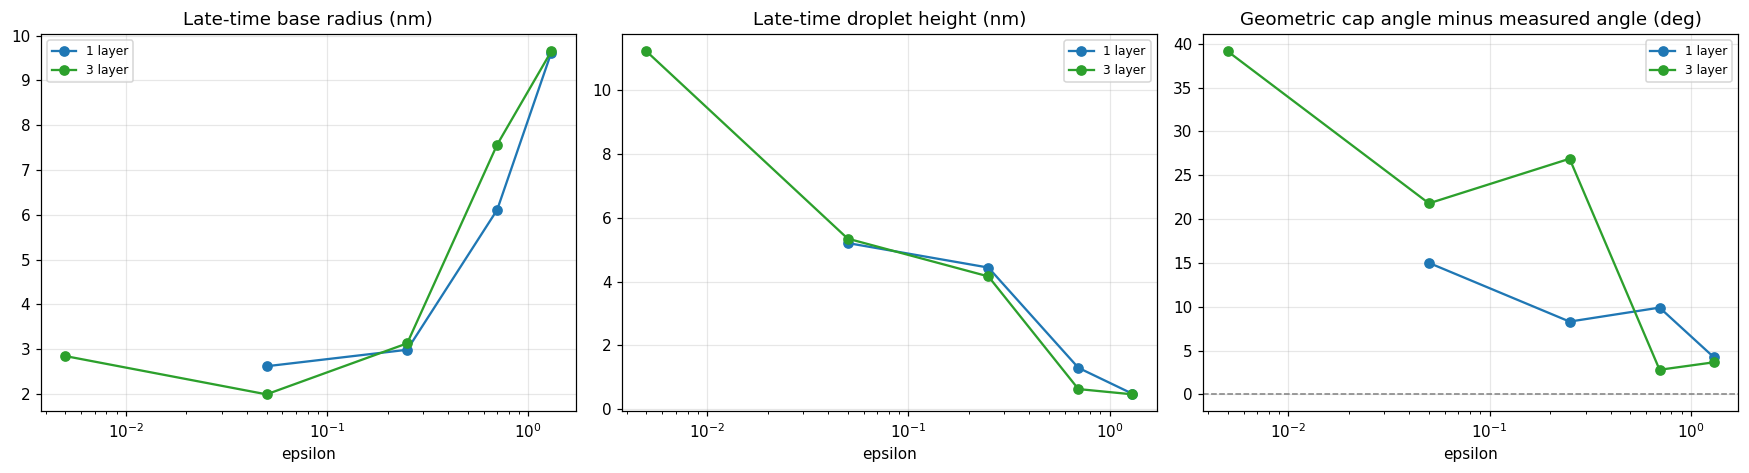

In [57]:
traj_sets = {n: f for n, f in LAYER_DATA.items() if all(c in f.columns for c in TRAJ_COLS)}
if traj_sets:
    rows = []
    for name, frame in traj_sets.items():
        for e in sorted(frame["epsilon"].unique()):
            late, is_late = late_window(frame, e)
            rows.append({
                "layers": name, "epsilon": e, "r_base": late["r_base"].mean(), "height": late["height"].mean(),
                "rg": late["rg"].mean(), "cap_bias": (late["cap_angle_est"] - late[TARGET]).mean(),
            })
    shape_tab = pd.DataFrame(rows)
    display(shape_tab.round(2))
    shape_tab.to_csv(os.path.join(OUT_DIR, "compare_layers_droplet_shape.csv"), index=False)
    fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
    for name in traj_sets:
        sub = shape_tab[shape_tab["layers"] == name].sort_values("epsilon")
        ax[0].semilogx(sub["epsilon"], sub["r_base"], "-o", color=LAYER_COLOR[name], label=name)
        ax[1].semilogx(sub["epsilon"], sub["height"], "-o", color=LAYER_COLOR[name], label=name)
        ax[2].semilogx(sub["epsilon"], sub["cap_bias"], "-o", color=LAYER_COLOR[name], label=name)
    ax[0].set_title("Late-time base radius (nm)")
    ax[1].set_title("Late-time droplet height (nm)")
    ax[2].set_title("Geometric cap angle minus measured angle (deg)")
    ax[2].axhline(0, color="gray", ls="--", lw=1)
    for a in ax:
        a.set_xlabel("epsilon")
        a.legend(fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print("trajectory features were not extracted for the datasets, droplet shape comparison skipped")

RMSE (deg) after-750 ps holdout


,1 layer,2 layer,3 layer
model,,,
Extra Trees,5.72,9.92,5.01
Random Forest,9.34,10.95,6.39
Polynomial Ridge,9.22,11.97,6.90
Ensemble (avg),6.38,9.87,6.52
Gradient Boosting,7.65,10.31,7.51
XGBoost,5.12,10.44,6.64
Gaussian Process,7.26,13.45,8.23
SVR,9.02,10.35,8.11
Neural Network (PyTorch),7.32,13.13,10.33


RMSE (deg) in-between (interpolation) holdout


,1 layer,2 layer,3 layer
model,,,
Extra Trees,5.96,4.11,6.88
Random Forest,6.24,4.49,7.66
Polynomial Ridge,5.75,5.85,7.21
Ensemble (avg),5.93,4.30,9.06
Gradient Boosting,6.45,4.63,8.23
XGBoost,6.69,5.11,8.44
Gaussian Process,6.20,4.49,9.59
SVR,7.28,5.22,11.06
Neural Network (PyTorch),6.86,4.90,14.06


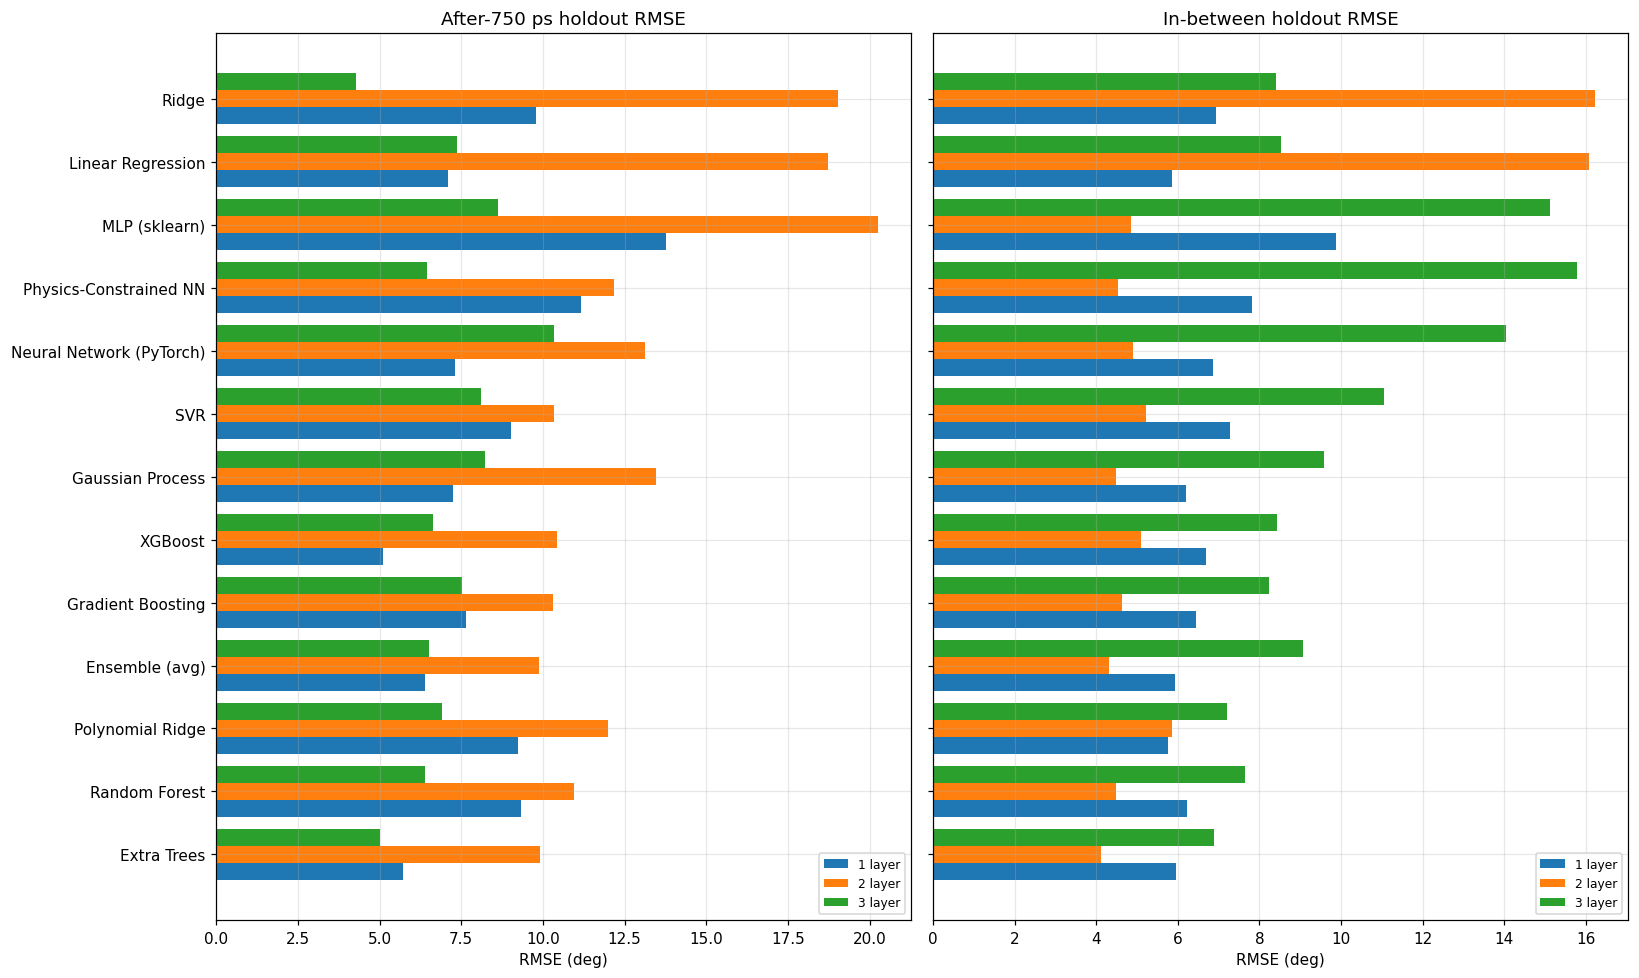

,best_after750,best_interpolation
1 layer,"(XGBoost, 5.12)","(Polynomial Ridge, 5.75)"
2 layer,"(Ensemble (avg), 9.87)","(Extra Trees, 4.11)"
3 layer,"(Ridge, 4.27)","(Extra Trees, 6.88)"


In [59]:
perf_sources = {
    "1 layer": (table_A_g1, table_C_g1),
    "2 layer": (table_A, table_C),
    "3 layer": (table_A_g3, table_C_g3),
}
perf_A = pd.DataFrame({n: pair[0].set_index("model")["RMSE"] for n, pair in perf_sources.items()})
perf_C = pd.DataFrame({n: pair[1].set_index("model")["RMSE"] for n, pair in perf_sources.items()})
order = perf_C.mean(axis=1).sort_values().index
perf_A = perf_A.loc[order]
perf_C = perf_C.loc[order]
print("RMSE (deg) after-750 ps holdout")
display(perf_A.round(2))
print("RMSE (deg) in-between (interpolation) holdout")
display(perf_C.round(2))
perf_A.to_csv(os.path.join(OUT_DIR, "compare_layers_model_rmse_after750.csv"))
perf_C.to_csv(os.path.join(OUT_DIR, "compare_layers_model_rmse_interpolation.csv"))

fig, ax = plt.subplots(1, 2, figsize=(15, 0.5 * len(order) + 2.5), sharey=True)
yy = np.arange(len(order))
for a, tab, title in [(ax[0], perf_A, "After-750 ps holdout RMSE"), (ax[1], perf_C, "In-between holdout RMSE")]:
    for j, name in enumerate(LAYER_DATA):
        a.barh(yy + (j - 1) * 0.27, tab[name].values, 0.27, color=LAYER_COLOR[name], label=name)
    a.set_yticks(yy)
    a.set_yticklabels(order)
    a.invert_yaxis()
    a.set_xlabel("RMSE (deg)")
    a.set_title(title)
    a.legend(fontsize=8)
plt.tight_layout()
plt.show()

best = pd.DataFrame({
    "best_after750": {n: (pair[0].iloc[0]["model"], round(float(pair[0].iloc[0]["RMSE"]), 2)) for n, pair in perf_sources.items()},
    "best_interpolation": {n: (pair[1].iloc[0]["model"], round(float(pair[1].iloc[0]["RMSE"]), 2)) for n, pair in perf_sources.items()},
})
display(best)